# Smart Home Appliances Manager – Beat the Electricity Bill!

## Project Introduction

The objective of this project is to analyse household electricity consumption and develop a Machine Learning-based system that can predict energy usage.

The project aims to help users understand household energy consumption patterns and estimate electricity costs. These insights will be used in an interactive game called **Smart Home Appliances Manager**, where players make decisions to manage electricity consumption while maintaining household comfort.

## Problem Statement

To predict household electricity consumption using historical power measurements, time-related features, and individual appliance usage patterns

## Dataset Source

The project uses the [REFIT Electrical Load Measurements dataset](https://pureportal.strath.ac.uk/en/datasets/refit-electrical-load-measurements/).
The REFIT dataset is a real-world residential electricity consumption dataset collected in the United Kingdom. The REFIT project monitored 20 residential households in and around Loughborough, Leicestershire, England, United Kingdom.

The data selected for this notebook is House 2, split across two downloaded raw CSV files. The raw measurements contain whole-house aggregate power and nine individual appliance-monitor channels. Power is recorded in watts (W), with readings at approximately 8-second intervals.
The appliances are referred by an appliance number throughout the project, here is the list of the appliance number and the real-life appliance it corresponds to:
1. Appliance1 – Fridge-Freezer
2. Appliance2 – Washing Machine
3. Appliance3 – Dishwasher
4. Appliance4 – Television
5. Appliance5 – Microwave
6. Appliance6 – Toaster
7. Appliance7 – Hi-Fi
8. Appliance8 – Kettle
9. Appliance9 – Oven Extractor Fan


## 2. Dataset Understanding

Before combining the files, we inspect their structure, timestamp coverage, repeated records, and agreement during the period covered by both files.

### 2.1 Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Loading the two raw files


In [2]:
raw_part1 = pd.read_csv('RAW_House2_Part1.csv')
raw_part2 = pd.read_csv('RAW_House2_Part2.csv')

print("Raw part 1 shape:", raw_part1.shape)
print("Raw part 2 shape:", raw_part2.shape)

part1 = raw_part1.copy(deep=True)
part2 = raw_part2.copy(deep=True)

print("Working copies created successfully!")


Raw part 1 shape: (3545248, 12)
Raw part 2 shape: (3669632, 12)
Working copies created successfully!


### 2.3 Inspecting the files

In [3]:
print("Part 1 columns:", part1.columns.tolist())
print("Part 2 columns:", part2.columns.tolist())

display(part1.head(1))
display(part2.head(1))

print("Part 1:")
print(part1.dtypes)
print("Part 2:")
print(part2.dtypes)

Part 1 columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']
Part 2 columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-09-17 23:08:11,1379459290,695,88,0,0,0,0,0,0,0,0


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,156.0,86.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Part 1:
Time          object
Unix           int64
Aggregate      int64
Appliance1     int64
Appliance2     int64
Appliance3     int64
Appliance4     int64
Appliance5     int64
Appliance6     int64
Appliance7     int64
Appliance8     int64
Appliance9     int64
dtype: object
Part 2:
Time           object
Unix            int64
Aggregate     float64
Appliance1    float64
Appliance2    float64
Appliance3    float64
Appliance4    float64
Appliance5    float64
Appliance6    float64
Appliance7    float64
Appliance8    float64
Appliance9    float64
dtype: object


### 2.4 Checking timestamp validity and Unix consistency

Time is used for merging because it is the human-readable measurement time. The Unix column is checked for consistency, but it is not used to decide whether two measurement records are duplicates. In the source outputs it differs from the second-resolution value derived from Time by at most one second.

In [4]:
def inspect_timestamps(data, name):

    time_values = pd.to_datetime(
        data["Time"], errors="coerce"
    )

    unix_values = pd.to_numeric(
        data["Unix"], errors="coerce"
    )

    # Identify rows containing valid timestamps
    valid = time_values.notna() & unix_values.notna()

    time_valid = time_values.loc[valid]
    unix_valid = unix_values.loc[valid]

    # Convert Time into Unix seconds
    # Assumption: Time is initially interpreted as UTC
    time_as_unix = (
        time_valid.astype("int64") // 10**9
    )

    # Calculate the difference between both timestamps
    difference = unix_valid - time_as_unix

    print("\n", name)

    print("\nTimestamp range:")
    print(time_values.min(), "to", time_values.max())

    print("\nTotal rows:", len(data))
    print("Invalid Time values:", time_values.isna().sum())
    print("Invalid Unix values:", unix_values.isna().sum())
    print("Valid timestamp comparisons:", valid.sum())

    print("\nDifference between Unix and Time (seconds):")
    print(difference.describe())

    print("\nMost common timestamp differences:")
    print(difference.value_counts().head(10))

    print("\nFirst 10 timestamp comparisons:")

    comparison = pd.DataFrame({
        "Time": time_valid.head(10),
        "Unix": unix_valid.head(10),
        "Time_as_Unix": time_as_unix.head(10),
        "Difference_sec": difference.head(10)
    })

    print(comparison.to_string(index=False))

    # Check whether all timestamps match exactly
    print("\nExact timestamp comparison:")

    if (difference == 0).all():
        print("All Unix timestamps match Time.")
    else:
        print("Unix timestamps do not all match Time.")

    return time_values


# Inspect Part 1
part1_times = inspect_timestamps(part1, "PART 1")

# Inspect Part 2
part2_times = inspect_timestamps(part2, "PART 2")


# Check whether the timestamp ranges overlap

part1_start = part1_times.min()
part1_end = part1_times.max()

part2_start = part2_times.min()
part2_end = part2_times.max()

print("\n\nOVERLAP CHECK")

print("\nPart 1:")
print(part1_start, "to", part1_end)

print("\nPart 2:")
print(part2_start, "to", part2_end)

if part1_start <= part2_end and part2_start <= part1_end:

    overlap_start = max(part1_start, part2_start)
    overlap_end = min(part1_end, part2_end)

    print("\nThe two datasets OVERLAP in time.")
    print("Overlap begins:", overlap_start)
    print("Overlap ends:", overlap_end)

    overlap_duration = overlap_end - overlap_start

    print("Overlap duration:", overlap_duration)

else:
    print("\nThe two datasets DO NOT OVERLAP in time.")



 PART 1

Timestamp range:
2013-09-17 23:08:11 to 2014-09-30 22:10:37

Total rows: 3545248
Invalid Time values: 0
Invalid Unix values: 0
Valid timestamp comparisons: 3545248

Difference between Unix and Time (seconds):
count    3.545248e+06
mean    -4.873820e-01
std      4.998408e-01
min     -1.000000e+00
25%     -1.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      0.000000e+00
dtype: float64

Most common timestamp differences:
 0    1817358
-1    1727890
Name: count, dtype: int64

First 10 timestamp comparisons:
               Time       Unix  Time_as_Unix  Difference_sec
2013-09-17 23:08:11 1379459290    1379459291              -1
2013-09-17 23:08:18 1379459297    1379459298              -1
2013-09-17 23:08:26 1379459306    1379459306               0
2013-09-17 23:08:34 1379459314    1379459314               0
2013-09-17 23:08:42 1379459321    1379459322              -1
2013-09-17 23:08:50 1379459329    1379459330              -1
2013-09-17 23:08:58 1379459338    137945

We find that the unix timestamps do not match the actual date-time values in the dataset, this is because of difference in timezone. Since, we do need only the time interval in between the readings, we can safely discard unix and use time column for time interval calculations.

In [5]:
# Convert Time to datetime
part1["Time"] = pd.to_datetime(part1["Time"], errors= "coerce")
part2["Time"] = pd.to_datetime(part2["Time"], errors= "coerce")

# Remove Unix column
part1 = part1.drop(columns=["Unix"])
part2 = part2.drop(columns=["Unix"])

print("Part 1 columns:", part1.columns.tolist())
print("Part 2 columns:", part2.columns.tolist())

Part 1 columns: ['Time', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']
Part 2 columns: ['Time', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']


Now, we combine both the datasets, since they have overlapping timestamps, and then remove these duplicates in subsequent data cleaning.

In [6]:
# Combine Part 1 and Part 2
combined = pd.concat(
    [part1, part2],
    ignore_index=True
)

# Sort according to timestamp
combined = combined.sort_values(
    by="Time"
).reset_index(drop=True)

print("Part 1 rows:", len(part1))
print("Part 2 rows:", len(part2))
print("Combined rows:", len(combined))

print("\nTimestamp range:")
print(combined["Time"].min(), "to", combined["Time"].max())

Part 1 rows: 3545248
Part 2 rows: 3669632
Combined rows: 7214880

Timestamp range:
2013-09-17 23:08:11 to 2015-05-28 08:05:43


## 3. Data Cleaning



In [7]:
# Measurement columns (excluding Time)
measurement_columns = [
    "Aggregate",
    "Appliance1", "Appliance2", "Appliance3",
    "Appliance4", "Appliance5", "Appliance6",
    "Appliance7", "Appliance8", "Appliance9"
]


### 3.1 Removing Duplicates

In [8]:
# Count duplicate timestamps
duplicate_count = combined["Time"].duplicated().sum()

print("Duplicate timestamp rows:", duplicate_count)


Duplicate timestamp rows: 654601


We check whether the measurement readings for the duplicated timestamps are same. If they are same, first occurence is kept, rest are discarded, if they are different, then the measurements are averaged.

In [9]:
print("Rows before duplicate removal:", len(combined))

# Remove records having identical Time and measurements
combined = combined.drop_duplicates(
    subset=["Time"] + measurement_columns,
    keep="first"
)

print("Rows after removing identical records:", len(combined))

# Group records having the same timestamp
combined = combined.groupby("Time", as_index=False).agg(
    {col: "mean" for col in measurement_columns}
)

# Sort chronologically
combined = combined.sort_values("Time").reset_index(drop=True)

print("Rows after duplicate removal:", len(combined))
print("Remaining duplicate timestamps:", combined["Time"].duplicated().sum())


Rows before duplicate removal: 7214880
Rows after removing identical records: 6695433
Rows after duplicate removal: 6560279
Remaining duplicate timestamps: 0


### 3.2 Missing Values

In [10]:
# Count missing values in every column
missing_count = combined.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_count / len(combined)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

print("Missing Value Analysis:")
print(missing_summary)

Missing Value Analysis:
            Missing Values  Missing Percentage (%)
Time                     0                0.000000
Aggregate           302667                4.613630
Appliance1          270621                4.125145
Appliance2          411625                6.274504
Appliance3          430119                6.556413
Appliance4          225975                3.444594
Appliance5          306528                4.672484
Appliance6          444459                6.775001
Appliance7          302803                4.615703
Appliance8          382517                5.830804
Appliance9          265990                4.054553


In [11]:

# Investigate missing values in the combined dataset

# Count rows with different numbers of missing readings
missing_per_row = combined[measurement_columns].isnull().sum(axis=1)

print("\nRows with no missing readings:",(missing_per_row == 0).sum())

print("Rows with all 10 readings missing:",(missing_per_row == 10).sum())

print("Rows with at least one missing reading:",(missing_per_row > 0).sum())

# Check whether Aggregate is missing
print("\nRows with missing Aggregate:",combined["Aggregate"].isnull().sum())

# Check whether all appliance readings are missing
appliance_columns = measurement_columns[1:]
all_appliances_missing = (combined[appliance_columns].isnull().all(axis=1))

print("Rows with all appliance readings missing:", all_appliances_missing.sum())



Rows with no missing readings: 4807931
Rows with all 10 readings missing: 0
Rows with at least one missing reading: 1752348

Rows with missing Aggregate: 302667
Rows with all appliance readings missing: 2204


In [12]:
appliance_columns = measurement_columns[1:]

# Aggregate missing, but at least one appliance reading is available
aggregate_missing_appliances_available = (
    combined["Aggregate"].isnull() &
    combined[appliance_columns].notnull().any(axis=1)
).sum()

# Aggregate available, but at least one appliance reading is missing
aggregate_available_appliances_missing = (
    combined["Aggregate"].notnull() &
    combined[appliance_columns].isnull().any(axis=1)
).sum()

print("Aggregate missing, but some appliances available:",
      aggregate_missing_appliances_available)

print("Aggregate available, but some appliances missing:",
      aggregate_available_appliances_missing)

Aggregate missing, but some appliances available: 302667
Aggregate available, but some appliances missing: 1449681


We do not remove rows where aggregate reading is missing and appliance reading is available because they can be used for appliance level analysis. If aggregate is available, but some or all appliances readings are absent, we can still use that to predict the energy consumption of the household, so we must keep these rows. However, they can't give us information about appliance level consumption.

### 3.3 Invalid or abnormal power readings (Outliers)

In [13]:
# Statistical summary of power measurements
power_summary = combined[measurement_columns].describe().T

print(power_summary)

                count        mean          std  min    25%    50%    75%  \
Aggregate   6257612.0  447.158793  1049.930461  0.0  105.0  163.0  297.0   
Appliance1  6289658.0   36.364481    49.351725  0.0    1.0    1.0   84.0   
Appliance2  6148654.0   17.827410   190.516030  0.0    0.0    0.0    0.0   
Appliance3  6130160.0   59.012508   388.353728  0.0    0.0    0.0    0.0   
Appliance4  6334304.0    3.972045    57.535801  0.0    0.0    0.0    0.0   
Appliance5  6253751.0    3.309469   105.678769  0.0    0.0    0.0    0.0   
Appliance6  6115820.0    2.900573   174.417351  0.0    0.0    0.0    0.0   
Appliance7  6257476.0    2.011997   149.265318  0.0    0.0    0.0    0.0   
Appliance8  6177762.0   23.331774   271.933574  0.0    0.0    0.0    0.0   
Appliance9  6294289.0    0.417083    55.616867  0.0    0.0    0.0    0.0   

                max  
Aggregate   24595.0  
Appliance1  32768.0  
Appliance2  98301.0  
Appliance3  98301.0  
Appliance4  65534.0  
Appliance5  98301.0  
Appliance

We see some suspiciously high readings for aggregate and all the appliances. The REFIT researchers specifically identified Individual Appliance Monitor (IAM) spikes above 4,000 W as invalid measurements, beacuse it was outside the sensor's rated limit. For now, we replace them with nan.

In [14]:

appliance_columns = measurement_columns[1:]

# Count suspicious appliance readings above 4000 W
high_reading_summary = pd.DataFrame({
    "Readings Above 4000 W": [
        (combined[col] > 4000).sum()
        for col in appliance_columns
    ],
    "Percentage (%)": [
        round((combined[col] > 4000).sum() /
              combined[col].notna().sum() * 100, 4)
        for col in appliance_columns
    ]
}, index=appliance_columns)

print("Appliance readings exceeding 4000 W:")
print(high_reading_summary)


Appliance readings exceeding 4000 W:
            Readings Above 4000 W  Percentage (%)
Appliance1                      7          0.0001
Appliance2                     55          0.0009
Appliance3                    197          0.0032
Appliance4                     62          0.0010
Appliance5                     89          0.0014
Appliance6                    867          0.0142
Appliance7                     78          0.0012
Appliance8                    127          0.0021
Appliance9                     49          0.0008


In [15]:
# Create a separate cleaned working DataFrame
combined_clean = combined.copy()

# Replace invalid appliance readings with NaN
for col in appliance_columns:
    combined_clean.loc[
        combined_clean[col] > 4000, col
    ] = float("nan")

print("Invalid appliance readings marked as NaN.")



Invalid appliance readings marked as NaN.


For checking outliers in aggregate, we use a boxplot for visualisation.

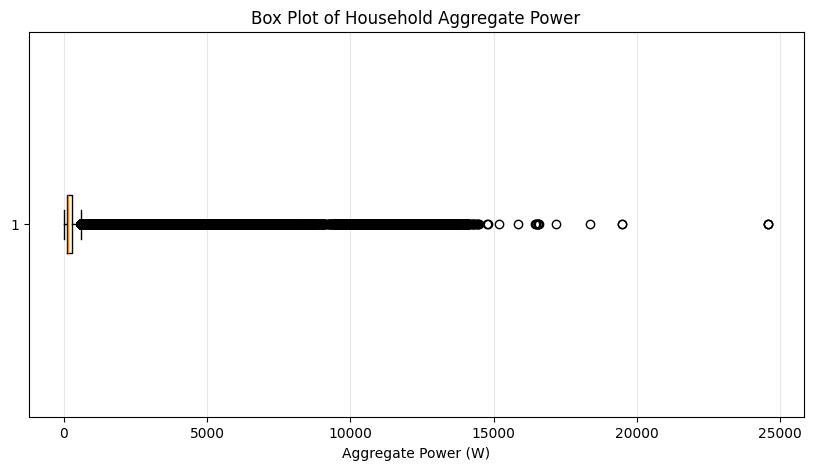

In [16]:
aggregate = combined_clean["Aggregate"].dropna()

plt.figure(figsize=(10, 5))

plt.boxplot(
    aggregate,
    vert=False,
    showfliers=True
)

plt.xlabel("Aggregate Power (W)")
plt.title("Box Plot of Household Aggregate Power")
plt.grid(axis="x", alpha=0.3)

plt.show()


The boxplot reveals that the distribution is extremely right-skewed, with a large number of statistically unusual high-power readings. But, we must not directly remove those, because there might be some genuine high power consumption intervals.

In [17]:

# Calculate IQR limits for Aggregate

aggregate = combined_clean["Aggregate"].dropna()

Q1 = aggregate.quantile(0.25)
Q3 = aggregate.quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# Count statistical outliers
outliers = aggregate[
    (aggregate < lower_fence) |
    (aggregate > upper_fence)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)

print("\nNumber of IQR outliers:", len(outliers))
print(
    "Percentage of IQR outliers:",
    round(len(outliers) / len(aggregate) * 100, 3),
    "%"
)


Q1: 105.0
Q3: 297.0
IQR: 192.0
Lower fence: -183.0
Upper fence: 585.0

Number of IQR outliers: 734455
Percentage of IQR outliers: 11.737 %


The upper fence is 585 W which is very low for a household power consumption, therefore using IQR fencing could result in deletion of genuine record.

We check temporal consistency, i.e whether there is an unusual spike between the aggregate readings in between the intervals to determine invalid readings.

In [18]:
# Create a separate DataFrame for temporal analysis
temporal = combined_clean[
    ["Time", "Aggregate"]
].copy()

# Ensure chronological ordering
temporal = temporal.sort_values("Time").reset_index(drop=True)

# Previous and next Aggregate readings
temporal["Previous"] = temporal["Aggregate"].shift(1)
temporal["Next"] = temporal["Aggregate"].shift(-1)

# Time difference between consecutive readings
temporal["Time_Gap"] = (
    temporal["Time"].diff().dt.total_seconds()
)

temporal["Next_Time_Gap"] = (
    temporal["Time_Gap"].shift(-1)
)

# Change in power compared with neighbouring readings
temporal["Change_From_Previous"] = (
    temporal["Aggregate"] - temporal["Previous"]
).abs()

temporal["Change_To_Next"] = (
    temporal["Aggregate"] - temporal["Next"]
).abs()

# Identify isolated peaks:
# Current reading is higher than both neighbouring readings
temporal["Isolated_Peak"] = (
    (temporal["Aggregate"] > temporal["Previous"]) &
    (temporal["Aggregate"] > temporal["Next"])
)

# Only consider cases where neighbouring timestamps
# are reasonably close to the nominal 8-second interval
temporal["Continuous_Interval"] = (
    (temporal["Time_Gap"] <= 16) &
    (temporal["Next_Time_Gap"] <= 16)
)

# Calculate how much the current reading exceeds
# its higher neighbouring reading
temporal["Peak_Excess"] = (
    temporal["Aggregate"] -
    temporal[["Previous", "Next"]].max(axis=1)
)

# Select isolated peaks with valid neighbouring intervals
suspicious_peaks = temporal[
    temporal["Isolated_Peak"] &
    temporal["Continuous_Interval"] &
    temporal["Aggregate"].notna() &
    temporal["Previous"].notna() &
    temporal["Next"].notna()
].copy()

# Display the 20 most prominent isolated peaks
suspicious_peaks = suspicious_peaks.sort_values(
    "Peak_Excess", ascending=False
)

print("20 Most prominent isolated Aggregate peaks:\n")

print(
    suspicious_peaks[
        ["Time", "Previous", "Aggregate", "Next",
         "Time_Gap", "Next_Time_Gap", "Peak_Excess"]
    ].head(20).to_string(index=False)
)

print("\nTotal isolated peaks investigated:",
      len(suspicious_peaks))


20 Most prominent isolated Aggregate peaks:

               Time  Previous  Aggregate   Next  Time_Gap  Next_Time_Gap  Peak_Excess
2014-04-27 10:57:07     159.0    16543.0  159.0       2.0           13.0      16384.0
2015-05-21 07:49:16     155.0    16538.0  154.0       7.0            7.0      16383.0
2015-02-19 16:07:55      81.0    16465.0   83.0       7.0            7.0      16382.0
2014-03-23 13:54:59     217.0    16598.0  216.0      12.0            2.0      16381.0
2014-07-12 08:03:36    2389.0    13191.0 2367.0       1.0            3.0      10802.0
2014-07-12 08:04:06    2353.0    12901.0 2359.0       4.0            4.0      10542.0
2014-08-14 17:52:00     116.0    10603.0  116.0       8.0            5.0      10487.0
2014-09-24 18:24:36     275.0    10756.0  277.0       2.0            6.0      10479.0
2014-09-24 08:14:51     322.0    10770.0  322.0       1.0            1.0      10448.0
2014-07-26 09:19:40     156.0    10600.0  154.0       1.0            3.0      10444.0
2014-07-2

Below is a visualisation of the temporal inconsistency that we are trying to fix.

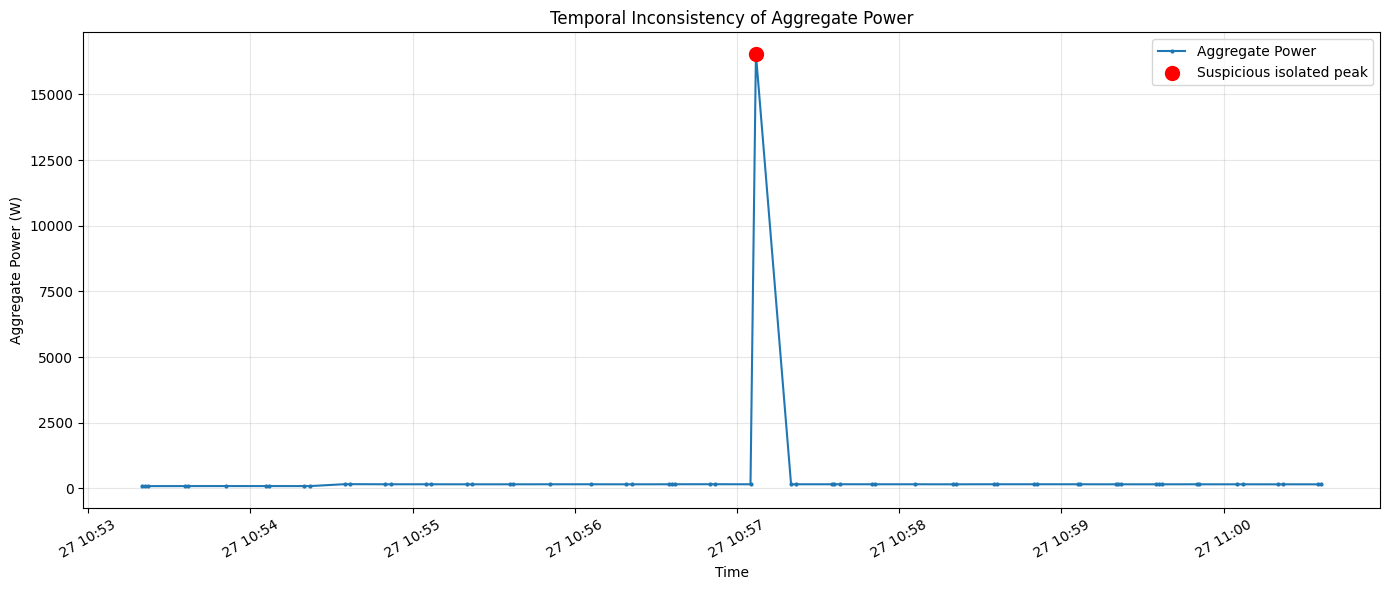

In [49]:
# Select the most prominent suspicious peak
if len(suspicious_peaks) > 0:

    peak_index = suspicious_peaks.index[0]

    # Show 30 readings before and after the selected peak
    start = max(0, peak_index - 30)
    end = min(len(temporal), peak_index + 31)

    plot_data = temporal.iloc[start:end]

    # Plot Aggregate power over time
    plt.figure(figsize=(14, 6))

    plt.plot(
        plot_data["Time"],
        plot_data["Aggregate"],
        label="Aggregate Power",
        marker=".",
        markersize=4
    )

    # Highlight the selected suspicious peak
    peak_time = temporal.loc[peak_index, "Time"]
    peak_value = temporal.loc[peak_index, "Aggregate"]

    plt.scatter(
        peak_time,
        peak_value,
        color="red",
        s=100,
        label="Suspicious isolated peak",
        zorder=5
    )

    plt.xlabel("Time")
    plt.ylabel("Aggregate Power (W)")
    plt.title("Temporal Inconsistency of Aggregate Power")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.show()

else:
    print("No isolated peaks found in the selected intervals.")


We try to isolate these peaks from the peaks that are normally possible and then use time-weighted liner interpolation, i.e. replace the spike with time weighted average of its neighbours.

In [20]:
# Preserve the original Aggregate readings


combined_clean["Aggregate_Original"] = combined_clean["Aggregate"]

# Create a temporary DataFrame for analysis

temporal = (
    combined_clean[["Time", "Aggregate"]]
    .sort_values("Time")
    .reset_index(drop=True)
)


# Obtain previous and next readings


temporal["P_prev"] = temporal["Aggregate"].shift(1)
temporal["P_next"] = temporal["Aggregate"].shift(-1)

temporal["T_prev"] = temporal["Time"].shift(1)
temporal["T_next"] = temporal["Time"].shift(-1)

# Calculate time gaps in seconds

temporal["dt_prev"] = (
    temporal["Time"] - temporal["T_prev"]
).dt.total_seconds()

temporal["dt_next"] = (
    temporal["T_next"] - temporal["Time"]
).dt.total_seconds()

# Calculate expected reading using time-weighted linear interpolation

temporal["Expected"] = (
    temporal["P_prev"]
    + (temporal["P_next"] - temporal["P_prev"])
    * temporal["dt_prev"]
    / (temporal["dt_prev"] + temporal["dt_next"])
)

# Calculate how much the actual reading exceeds the expected reading
temporal["Excess"] = (
    temporal["Aggregate"] - temporal["Expected"]
)

# Check whether neighbouring readings are reasonably close to each other

neighbour_difference = (
    temporal["P_prev"] - temporal["P_next"]
).abs()

neighbour_limit = np.maximum(
    500,
    0.20 * temporal[["P_prev", "P_next"]].max(axis=1)
)

similar_neighbours = (
    neighbour_difference <= neighbour_limit
)


# Check whether neighbouring readings and timestamps are valid

valid_neighbours = (
    temporal["Aggregate"].notna()
    & temporal["P_prev"].notna()
    & temporal["P_next"].notna()
)

close_timestamps = (
    (temporal["dt_prev"] > 0)
    & (temporal["dt_next"] > 0)
    & (temporal["dt_prev"] <= 16)
    & (temporal["dt_next"] <= 16)
)

# Apply the 8000 W excess threshold

THRESHOLD = 8000

temporal["Potential_Fault"] = (
    valid_neighbours
    & close_timestamps
    & similar_neighbours
    & (temporal["Excess"] >= THRESHOLD)
)

# Count flagged readings

flagged_count = int(temporal["Potential_Fault"].sum())

total_readings = len(temporal)

not_flagged = total_readings - flagged_count

percentage_flagged = (
    flagged_count / total_readings
) * 100

# Display results

print("\nAGGREGATE FAULT DETECTION RESULTS")

print(f"Total Aggregate readings : {total_readings:,}")
print(f"Readings flagged         : {flagged_count:,}")
print(f"Readings not flagged     : {not_flagged:,}")

print(f"Percentage flagged      : {percentage_flagged:.4f}%")


# Display the 20 most suspicious readings

candidates = temporal[
    temporal["Potential_Fault"]
].copy()

candidates = candidates.sort_values(
    "Excess", ascending=False
)

print("\n20 MOST SUSPICIOUS AGGREGATE READINGS")

print(
    candidates[
        [
            "Time",
            "P_prev",
            "Aggregate",
            "P_next",
            "Expected",
            "Excess",
            "dt_prev",
            "dt_next"
        ]
    ].head(20).to_string(index=False)
)



AGGREGATE FAULT DETECTION RESULTS
Total Aggregate readings : 6,560,279
Readings flagged         : 242
Readings not flagged     : 6,560,037
Percentage flagged      : 0.0037%

20 MOST SUSPICIOUS AGGREGATE READINGS
               Time  P_prev  Aggregate  P_next    Expected       Excess  dt_prev  dt_next
2014-04-27 10:57:07   159.0    16543.0   159.0  159.000000 16384.000000      2.0     13.0
2015-05-21 07:49:16   155.0    16538.0   154.0  154.500000 16383.500000      7.0      7.0
2015-02-19 16:07:55    81.0    16465.0    83.0   82.000000 16383.000000      7.0      7.0
2014-03-23 13:54:59   217.0    16598.0   216.0  216.142857 16381.857143     12.0      2.0
2014-07-12 08:03:36  2389.0    13191.0  2367.0 2383.500000 10807.500000      1.0      3.0
2014-07-12 08:04:06  2353.0    12901.0  2359.0 2356.000000 10545.000000      4.0      4.0
2014-08-14 17:52:00   116.0    10603.0   116.0  116.000000 10487.000000      8.0      5.0
2014-09-24 18:24:36   275.0    10756.0   277.0  275.500000 10480.50

This summary shows how many aggregate readings were flag and what percentage they were.

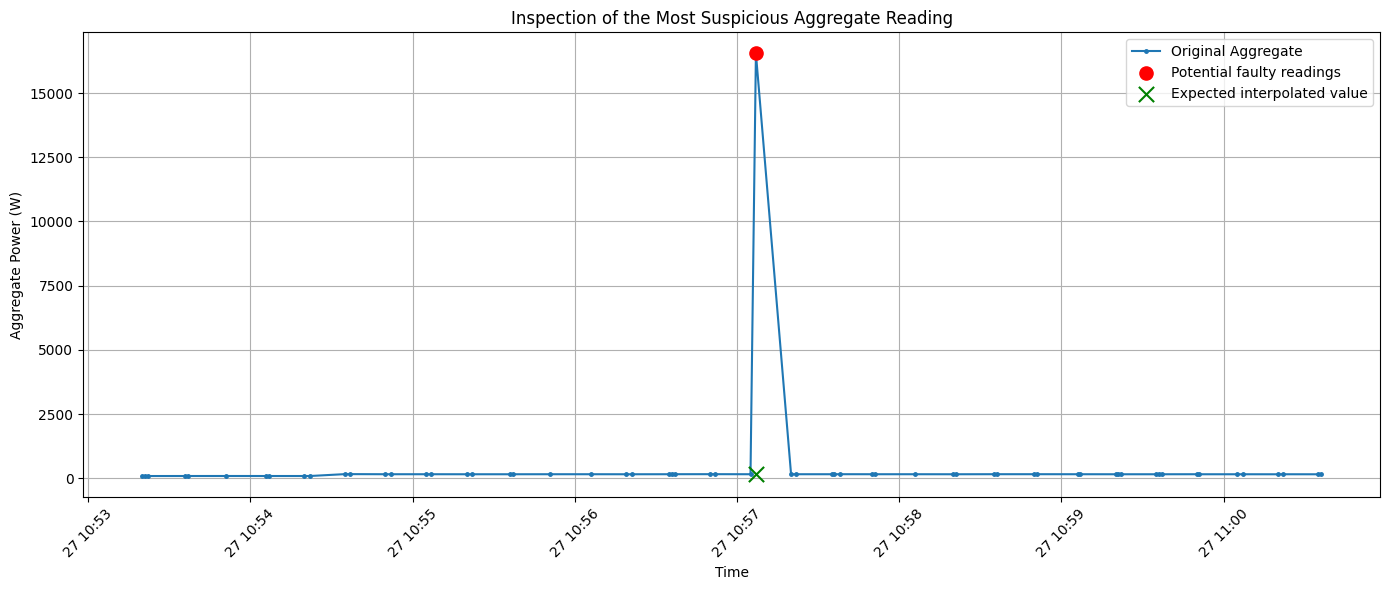

In [21]:

import matplotlib.pyplot as plt

# Select the reading with the highest excess
selected = candidates.sort_values(
    "Excess", ascending=False
).iloc[0]

# Get its position in the temporal DataFrame
pos = temporal.index[
    temporal["Time"] == selected["Time"]
][0]

# Select 30 readings before and after it
start = max(0, pos - 30)
end = min(len(temporal), pos + 31)

plot_data = temporal.iloc[start:end]

plt.figure(figsize=(14, 6))

# Plot original Aggregate readings
plt.plot(
    plot_data["Time"],
    plot_data["Aggregate"],
    marker=".",
    markersize=5,
    label="Original Aggregate"
)

# Highlight flagged readings in this time window
local_candidates = candidates[
    (candidates["Time"] >= plot_data["Time"].min())
    & (candidates["Time"] <= plot_data["Time"].max())
]

plt.scatter(
    local_candidates["Time"],
    local_candidates["Aggregate"],
    color="red",
    s=90,
    label="Potential faulty readings",
    zorder=5
)

# Mark the expected value for the selected reading
plt.scatter(
    [selected["Time"]],
    [selected["Expected"]],
    color="green",
    marker="x",
    s=120,
    label="Expected interpolated value",
    zorder=6
)

plt.xlabel("Time")
plt.ylabel("Aggregate Power (W)")
plt.title("Inspection of the Most Suspicious Aggregate Reading")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


This is a visulaization of our correction using interpolation.

In [22]:
# Preserve the original Aggregate column

combined_clean["Aggregate_Original"] = combined_clean["Aggregate"]

# Create a corrected Aggregate column

combined_clean["Aggregate_Corrected"] = combined_clean["Aggregate"]

# Get the positions of flagged readings

flagged_positions = temporal.index[
    temporal["Potential_Fault"]
].to_numpy()

# Perform time-weighted interpolation

for pos in flagged_positions:

    # Previous and next readings
    P_prev = temporal.loc[pos, "P_prev"]
    P_next = temporal.loc[pos, "P_next"]

    # Time intervals
    dt_prev = temporal.loc[pos, "dt_prev"]
    dt_next = temporal.loc[pos, "dt_next"]

    # Time-weighted interpolated value
    P_interpolated = (
        P_prev
        + (P_next - P_prev)
        * dt_prev
        / (dt_prev + dt_next)
    )

    # Get the corresponding row in combined_clean
    original_position = combined_clean.index[
        combined_clean["Time"] == temporal.loc[pos, "Time"]
    ][0]

    # Replace only the flagged Aggregate reading
    combined_clean.loc[
        original_position, "Aggregate_Corrected"
    ] = P_interpolated

# Count corrected readings

changed_mask = (
    combined_clean["Aggregate_Original"].notna()
    & combined_clean["Aggregate_Corrected"].notna()
    & (
        combined_clean["Aggregate_Original"]
        != combined_clean["Aggregate_Corrected"]
    )
)

corrected_count = changed_mask.sum()

print("INTERPOLATION VERIFICATION")

print("Total flagged readings:", len(flagged_positions))
print("Actual readings corrected:", corrected_count)

print(
    "Remaining flagged readings:",
    len(flagged_positions) - corrected_count
)


INTERPOLATION VERIFICATION
Total flagged readings: 242
Actual readings corrected: 242
Remaining flagged readings: 0


The above block executes time-weighted interpolation and shows flagged and corrected readings.

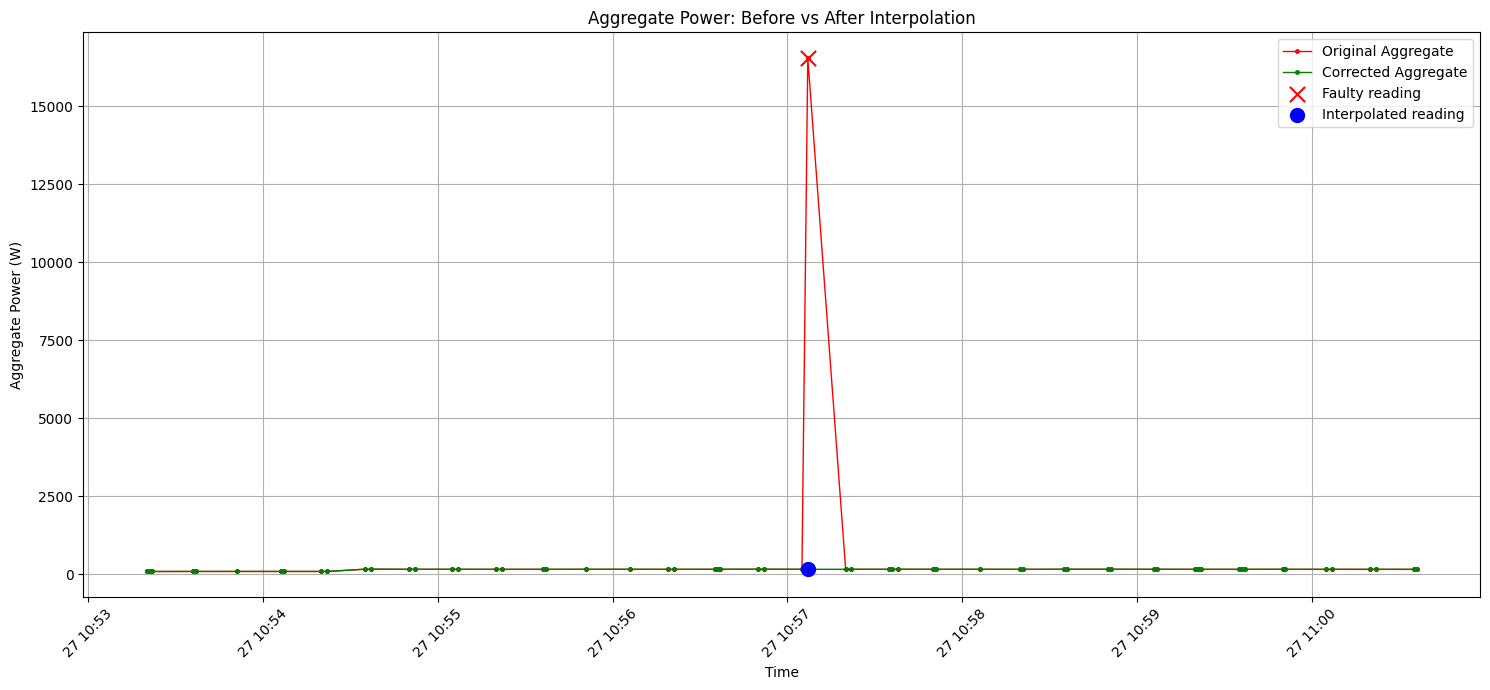

INTERPOLATION COMPARISON
Timestamp: 2014-04-27 10:57:07
Original reading: 16543.0 W
Interpolated reading: 159.0 W


In [23]:
# Select the most suspicious corrected reading

selected = candidates.sort_values(
    "Excess", ascending=False
).iloc[0]

selected_time = selected["Time"]

# Find its position in the dataset

pos = combined_clean.index[
    combined_clean["Time"] == selected_time
][0]

# Select 30 readings before and after

start = max(0, pos - 30)
end = min(len(combined_clean), pos + 31)

plot_data = combined_clean.iloc[start:end]

# Plot original and corrected readings

plt.figure(figsize=(15, 7))

# Original Aggregate readings (including faulty spike)
plt.plot(
    plot_data["Time"],
    plot_data["Aggregate_Original"],
    color="red",
    marker=".",
    markersize=5,
    linewidth=1,
    label="Original Aggregate"
)

# Corrected Aggregate readings
plt.plot(
    plot_data["Time"],
    plot_data["Aggregate_Corrected"],
    color="green",
    marker=".",
    markersize=5,
    linewidth=1,
    label="Corrected Aggregate"
)

# Highlight the faulty original reading
plt.scatter(
    [selected_time],
    [selected["Aggregate"]],
    color="red",
    s=120,
    marker="x",
    label="Faulty reading",
    zorder=5
)

# Highlight the interpolated reading
plt.scatter(
    [selected_time],
    [selected["Expected"]],
    color="blue",
    s=100,
    marker="o",
    label="Interpolated reading",
    zorder=6
)

plt.xlabel("Time")
plt.ylabel("Aggregate Power (W)")
plt.title("Aggregate Power: Before vs After Interpolation")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Print numerical comparison

print("INTERPOLATION COMPARISON")
print("Timestamp:", selected_time)
print("Original reading:", selected["Aggregate"], "W")
print("Interpolated reading:", selected["Expected"], "W")


This graph shows visualization of an example of correction done via time weighted linear interpolation.

In [24]:
# Select the corrected power columns
cleaned_columns = [
    "Aggregate_Corrected",
    "Appliance1", "Appliance2", "Appliance3",
    "Appliance4", "Appliance5", "Appliance6",
    "Appliance7", "Appliance8", "Appliance9"
]

cleaned_summary = combined_clean[cleaned_columns].describe().T

# Add missing value counts and percentages
cleaned_summary["Missing_Count"] = (
    combined_clean[cleaned_columns].isna().sum()
)

cleaned_summary["Missing_Percentage"] = (
    combined_clean[cleaned_columns].isna().mean() * 100
)

print("STATISTICAL SUMMARY AFTER OUTLIER CORRECTION")
print(cleaned_summary.round(2))


STATISTICAL SUMMARY AFTER OUTLIER CORRECTION
                         count    mean      std  min    25%    50%    75%  \
Aggregate_Corrected  6257612.0  446.77  1048.09  0.0  105.0  163.0  297.0   
Appliance1           6289651.0   36.35    45.82  0.0    1.0    1.0   84.0   
Appliance2           6148599.0   17.64   170.82  0.0    0.0    0.0    0.0   
Appliance3           6129963.0   58.35   343.25  0.0    0.0    0.0    0.0   
Appliance4           6334242.0    3.85    13.30  0.0    0.0    0.0    0.0   
Appliance5           6253662.0    3.08    56.81  0.0    0.0    0.0    0.0   
Appliance6           6114953.0    1.44    36.62  0.0    0.0    0.0    0.0   
Appliance7           6257398.0    1.62     5.52  0.0    0.0    0.0    0.0   
Appliance8           6177635.0   22.99   248.25  0.0    0.0    0.0    0.0   
Appliance9           6294240.0    0.31     4.90  0.0    0.0    0.0    0.0   

                         max  Missing_Count  Missing_Percentage  
Aggregate_Corrected  24595.0         3026

This is the summary after outlier correction, and the updated box plot.

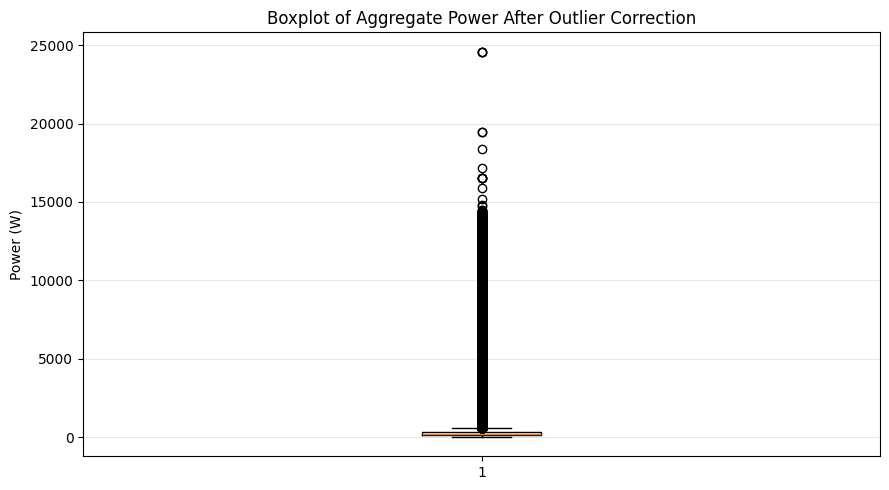

In [25]:
# Plot corrected Aggregate power
plt.figure(figsize=(9, 5))

plt.boxplot(
    combined_clean["Aggregate_Corrected"].dropna(),
    vert=True
)

plt.ylabel("Power (W)")
plt.title("Boxplot of Aggregate Power After Outlier Correction")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


We still see that there are many readings that are way too high, we check if they are sudden spikes or sustained high consumptions.

In [26]:
high_power = combined_clean[
    combined_clean["Aggregate_Corrected"] > 8000
].copy()

high_power = high_power.sort_values("Time").reset_index(drop=True)

high_power["Time_Gap"] = (
    high_power["Time"].diff().dt.total_seconds()
)

high_power["New_Event"] = (
    high_power["Time_Gap"].isna()
    | (high_power["Time_Gap"] > 16)
)

high_power["Event_ID"] = high_power["New_Event"].cumsum()

event_summary = high_power.groupby("Event_ID").agg(
    Start_Time=("Time", "min"),
    End_Time=("Time", "max"),
    Readings=("Aggregate_Corrected", "count"),
    Maximum_Power=("Aggregate_Corrected", "max"),
    Average_Power=("Aggregate_Corrected", "mean")
).reset_index(drop=True)

event_summary["Duration_Seconds"] = (
    event_summary["End_Time"] - event_summary["Start_Time"]
).dt.total_seconds()

print(event_summary.sort_values(
    "Maximum_Power", ascending=False
).head(30).to_string(index=False))

         Start_Time            End_Time  Readings  Maximum_Power  Average_Power  Duration_Seconds
2014-05-28 09:23:20 2014-05-28 09:23:22         3        24595.0   24595.000000               2.0
2014-03-23 09:41:13 2014-03-23 09:44:18        33        19479.0   13563.545455             185.0
2014-11-29 17:20:19 2014-11-29 17:22:31        19        18353.0   14008.842105             132.0
2014-04-28 17:08:21 2014-04-28 17:08:24         2        16540.0   16540.000000               3.0
2014-05-22 10:05:35 2014-05-22 10:05:36         2        16497.0   16497.000000               1.0
2015-05-03 10:03:55 2015-05-03 10:04:49         9        14413.0   13797.222222              54.0
2014-10-12 17:42:28 2014-10-12 17:43:16         7        14350.0   13889.714286              48.0
2014-10-12 17:36:29 2014-10-12 17:41:56        40        14326.0   12665.625000             327.0
2013-10-23 08:54:46 2013-10-23 09:01:18        60        14192.0   13703.183333             392.0
2014-10-12 17:44:52 

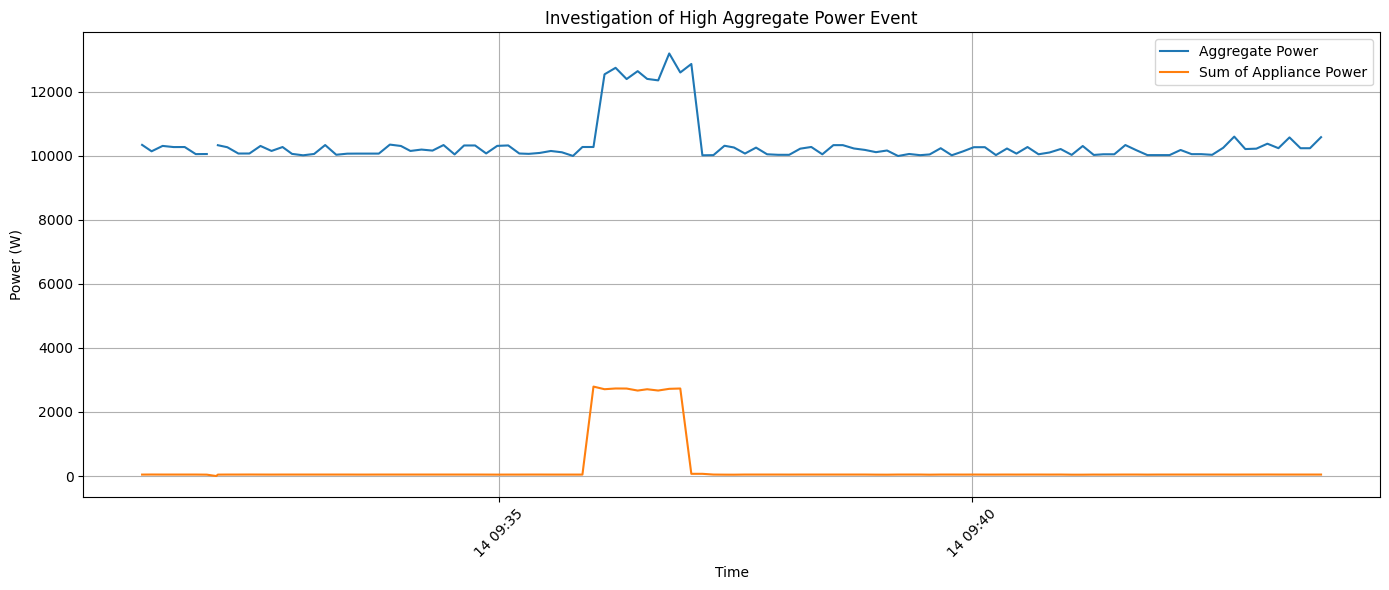

In [27]:
import matplotlib.pyplot as plt

start_time = pd.Timestamp("2015-03-14 09:31:14")
end_time = pd.Timestamp("2015-03-14 09:43:41")

event_data = combined_clean[
    (combined_clean["Time"] >= start_time) &
    (combined_clean["Time"] <= end_time)
].copy()

event_data = event_data.sort_values("Time")

event_data["Appliance_Sum"] = event_data[
    appliance_columns
].sum(axis=1, min_count=1)

plt.figure(figsize=(14, 6))

plt.plot(
    event_data["Time"],
    event_data["Aggregate_Corrected"],
    label="Aggregate Power"
)

plt.plot(
    event_data["Time"],
    event_data["Appliance_Sum"],
    label="Sum of Appliance Power"
)

plt.xlabel("Time")
plt.ylabel("Power (W)")
plt.title("Investigation of High Aggregate Power Event")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

We can see from these graphs that for some time, when the aggregate power increases, the sum of power of appliances also changes which suggess that these might be real readings.

There are many outliers, this is because the energy consumption data is right skewed, these may be real events or sensor faults. To distinguish these, we use a majority voting method, we detect outliers via 3 methods Rolling IQR, Rolling Percentile & Rolling Median. If two or more methods detect an anomaly, we flag it as an outlier.

In [28]:
# Sort data chronologically
combined_clean = combined_clean.sort_values("Time").reset_index(drop=True)

# Use the Aggregate readings after the previous isolated-spike correction
aggregate = (
    combined_clean.set_index("Time")["Aggregate_Corrected"]
)

# Method 1: Rolling IQR
q1 = aggregate.rolling(
    "1h", center=True, min_periods=30
).quantile(0.25)

q3 = aggregate.rolling(
    "1h", center=True, min_periods=30
).quantile(0.75)

iqr = q3 - q1

lower_iqr = q1 - 3 * iqr
upper_iqr = q3 + 3 * iqr

iqr_mask = (
    (aggregate < lower_iqr) |
    (aggregate > upper_iqr)
)

# Method 2: Rolling Percentile
lower_percentile = aggregate.rolling(
    "1h", center=True, min_periods=30
).quantile(0.005)

upper_percentile = aggregate.rolling(
    "1h", center=True, min_periods=30
).quantile(0.995)

percentile_mask = (
    (aggregate < lower_percentile) |
    (aggregate > upper_percentile)
)

# Method 3: Rolling Median and Standard Deviation
rolling_median = aggregate.rolling(
    "1h", center=True, min_periods=30
).median()

rolling_std = aggregate.rolling(
    "1h", center=True, min_periods=30
).std()

lower_std = rolling_median - 6 * rolling_std
upper_std = rolling_median + 6 * rolling_std

std_mask = (
    (aggregate < lower_std) |
    (aggregate > upper_std)
)

# Treat negative power readings as invalid
negative_mask = aggregate < 0

iqr_mask = (iqr_mask | negative_mask).fillna(False)
percentile_mask = (percentile_mask | negative_mask).fillna(False)
std_mask = (std_mask | negative_mask).fillna(False)

# Compare detection results
comparison = pd.DataFrame({
    "Method": [
        "Rolling IQR",
        "Rolling Percentile",
        "Rolling Median + Std"
    ],
    "Detected": [
        iqr_mask.sum(),
        percentile_mask.sum(),
        std_mask.sum()
    ],
    "Percentage": [
        iqr_mask.mean() * 100,
        percentile_mask.mean() * 100,
        std_mask.mean() * 100
    ]
})

print("ANOMALY DETECTION COMPARISON")
print(comparison.round(4).to_string(index=False))

# Calculate agreement between methods
votes = (
    iqr_mask.astype(int) +
    percentile_mask.astype(int) +
    std_mask.astype(int)
)

print("\nMETHOD AGREEMENT")
print("Detected by all 3:", (votes == 3).sum())
print("Detected by at least 2:", (votes >= 2).sum())
print("Detected by only 1:", (votes == 1).sum())
print("Not detected:", (votes == 0).sum())

# Final anomaly decision: majority voting
final_anomaly_mask = votes >= 2

# Create final cleaned Aggregate column
combined_clean["Aggregate_Final"] = aggregate.to_numpy()

combined_clean.loc[
    final_anomaly_mask.to_numpy(),
    "Aggregate_Final"
] = np.nan

# Final results
print("\nFINAL AGGREGATE CLEANING RESULTS")

print("Total readings:", len(aggregate))
print("Detected anomalies:", final_anomaly_mask.sum())

print(
    "Percentage removed:",
    round(final_anomaly_mask.mean() * 100, 4), "%"
)

print(
    "Total missing readings:",
    combined_clean["Aggregate_Final"].isna().sum()
)

print("\nFinal Aggregate statistics:")
print(combined_clean["Aggregate_Final"].describe())


ANOMALY DETECTION COMPARISON
              Method  Detected  Percentage
         Rolling IQR    259787      3.9600
  Rolling Percentile     31607      0.4818
Rolling Median + Std      6126      0.0934

METHOD AGREEMENT
Detected by all 3: 2282
Detected by at least 2: 15040
Detected by only 1: 265158
Not detected: 6280081

FINAL AGGREGATE CLEANING RESULTS
Total readings: 6560279
Detected anomalies: 15040
Percentage removed: 0.2293 %
Total missing readings: 317707

Final Aggregate statistics:
count    6.242572e+06
mean     4.393649e+02
std      1.027666e+03
min      0.000000e+00
25%      1.050000e+02
50%      1.630000e+02
75%      2.940000e+02
max      1.520600e+04
Name: Aggregate_Final, dtype: float64


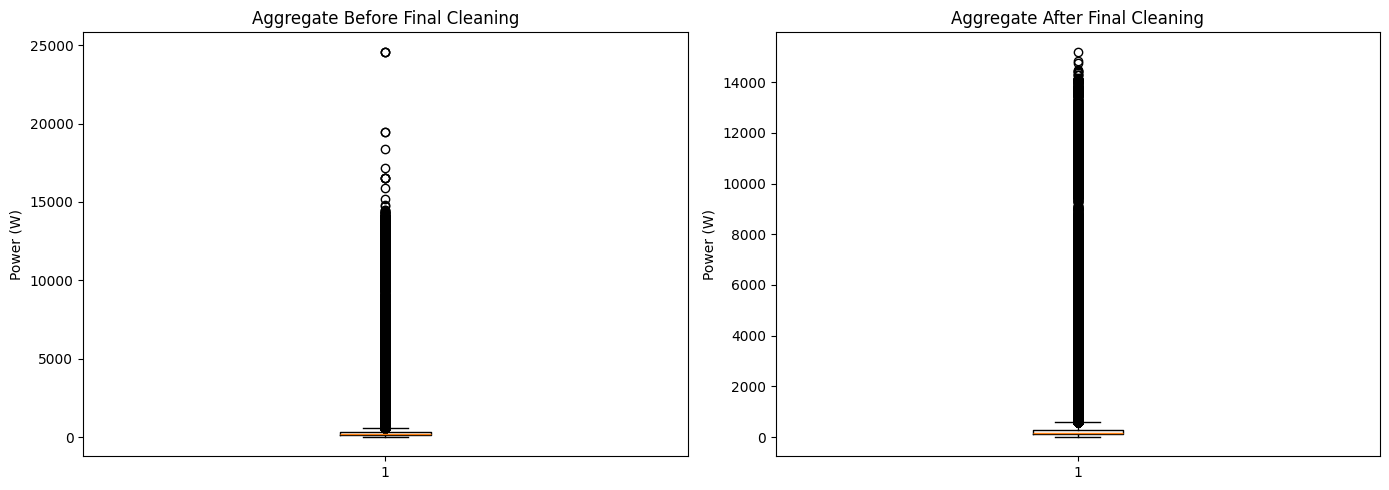

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(
    combined_clean["Aggregate_Corrected"].dropna()
)
axes[0].set_title("Aggregate Before Final Cleaning")
axes[0].set_ylabel("Power (W)")

axes[1].boxplot(
    combined_clean["Aggregate_Final"].dropna()
)
axes[1].set_title("Aggregate After Final Cleaning")
axes[1].set_ylabel("Power (W)")

plt.tight_layout()
plt.show()

Box plot showing changes in the data before and after cleaning outliers.

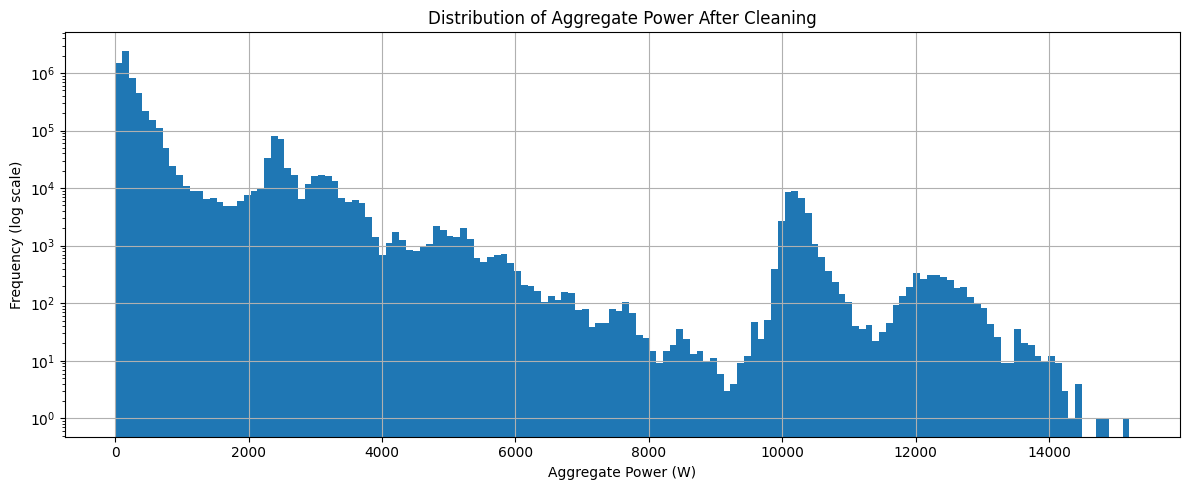

In [30]:
plt.figure(figsize=(12, 5))

plt.hist(
    combined_clean["Aggregate_Final"].dropna(),
    bins=150,
    log=True
)

plt.xlabel("Aggregate Power (W)")
plt.ylabel("Frequency (log scale)")
plt.title("Distribution of Aggregate Power After Cleaning")

plt.grid(True)
plt.tight_layout()
plt.show()

This histogram gives a visual understanding of how the data of aggregate column looks on a log scale after cleaning the outliers.

### 3.4 Checking for frequencies of different time intervals

In [31]:

# Sort the dataset chronologically
combined_clean = combined_clean.sort_values("Time").reset_index(drop=True)

# Calculate differences between consecutive timestamps
time_intervals = (
    combined_clean["Time"].diff().dt.total_seconds()
)

# Count the frequency of each time interval
interval_counts = time_intervals.value_counts().sort_index()

print("Zero-second intervals:",
      (time_intervals == 0).sum())

print("Negative intervals:",
      (time_intervals < 0).sum())

print("Intervals from 1 to 15 seconds:",
      ((time_intervals >= 1) & (time_intervals <= 15)).sum())

print("Intervals from 16 to 60 seconds:",
      ((time_intervals > 15) & (time_intervals <= 60)).sum())

print("Intervals above 60 seconds:",
      (time_intervals > 60).sum())

print("Missing intervals:",
      time_intervals.isna().sum())


Zero-second intervals: 0
Negative intervals: 0
Intervals from 1 to 15 seconds: 6545420
Intervals from 16 to 60 seconds: 12421
Intervals above 60 seconds: 2437
Missing intervals: 1


An interval is excluded if:
1. Either of its two Aggregate power readings was missing.
2. Its time difference was zero or negative.
3. Its time difference exceeded 15 seconds.

In the next part, we calculate the energy consumed by the household in each valid time interval.

In [32]:

# Sort readings chronologically
combined_clean = combined_clean.sort_values("Time").reset_index(drop=True)

# Calculate actual time difference
combined_clean["Time_Difference"] = (
    combined_clean["Time"].diff().dt.total_seconds()
)

# Get previous Aggregate power
previous_power = combined_clean["Aggregate_Final"].shift(1)

# Identify valid intervals
valid_intervals = (
    combined_clean["Aggregate_Final"].notna()
    & previous_power.notna()
    & (combined_clean["Time_Difference"] > 0)
    & (combined_clean["Time_Difference"] <= 15)
)

# Calculate energy in Wh using trapezoidal integration
combined_clean["Energy_Wh"] = np.nan

combined_clean.loc[valid_intervals, "Energy_Wh"] = (
    (
        combined_clean.loc[valid_intervals, "Aggregate_Final"]
        + previous_power.loc[valid_intervals]
    ) / 2
    * combined_clean.loc[valid_intervals, "Time_Difference"]
    / 3600
)

# Convert energy into kWh
combined_clean["Energy_kWh"] = (
    combined_clean["Energy_Wh"] / 1000
)

# Display energy statistics
print("ENERGY CONSUMPTION STATISTICS")

print("\nEnergy in Wh:")
print(combined_clean["Energy_Wh"].describe())

print("\nEnergy in kWh:")
print(combined_clean["Energy_kWh"].describe())

print("\nTotal observed energy:")
print(round(combined_clean["Energy_Wh"].sum(), 2), "Wh")
print(round(combined_clean["Energy_kWh"].sum(), 4), "kWh")

print("\nINTERVAL COVERAGE")
print("Valid intervals:", valid_intervals.sum())
print("Excluded intervals:", len(valid_intervals) - valid_intervals.sum())
print(
    "Valid interval percentage:",
    round(valid_intervals.mean() * 100, 2), "%"
)


ENERGY CONSUMPTION STATISTICS

Energy in Wh:
count    5.965692e+06
mean     7.462426e-01
std      2.007959e+00
min      0.000000e+00
25%      1.308333e-01
50%      2.693056e-01
75%      5.916667e-01
max      5.735000e+01
Name: Energy_Wh, dtype: float64

Energy in kWh:
count    5.965692e+06
mean     7.462426e-04
std      2.007959e-03
min      0.000000e+00
25%      1.308333e-04
50%      2.693056e-04
75%      5.916667e-04
max      5.735000e-02
Name: Energy_kWh, dtype: float64

Total observed energy:
4451853.45 Wh
4451.8535 kWh

INTERVAL COVERAGE
Valid intervals: 5965692
Excluded intervals: 594587
Valid interval percentage: 90.94 %


## 4. Feature Engineering

In [33]:
# Define appliance columns
appliance_columns = [
    "Appliance1", "Appliance2", "Appliance3",
    "Appliance4", "Appliance5", "Appliance6",
    "Appliance7", "Appliance8", "Appliance9"
]

# Sort data chronologically
combined_clean = (
    combined_clean
    .sort_values("Time")
    .reset_index(drop=True)
)

# Identify the power columns to process
power_columns = ["Aggregate_Final"] + appliance_columns

# Calculate actual time difference between consecutive readings
time_difference = (
    combined_clean["Time"]
    .diff()
    .dt.total_seconds()
)

# Create a separate dataframe for interval energy
interval_data = pd.DataFrame({
    "Time": combined_clean["Time"]
})

# Calculate energy consumption for household and each appliance
for col in power_columns:

    current_power = combined_clean[col]
    previous_power = current_power.shift(1)

    # Identify valid intervals for this power channel
    valid_intervals = (
        current_power.notna()
        & previous_power.notna()
        & (time_difference > 0)
        & (time_difference <= 15)
    )

    # Calculate energy in Wh using trapezoidal integration
    interval_energy = pd.Series(
        np.nan,
        index=combined_clean.index
    )

    interval_energy.loc[valid_intervals] = (
        (
            current_power.loc[valid_intervals]
            + previous_power.loc[valid_intervals]
        ) / 2
        * time_difference.loc[valid_intervals]
        / 3600
    )

    # Convert Wh to kWh
    interval_data[col.replace("_Final", "") + "_Energy_kWh"] = (
        interval_energy / 1000
    )

# Set timestamp as index for monthly aggregation
interval_data = interval_data.set_index("Time")

# Calculate monthly energy consumption
monthly_energy = interval_data.resample("MS").sum(min_count=1)

# Rename household energy column
monthly_energy = monthly_energy.rename(
    columns={"Aggregate_Energy_kWh": "Monthly_Household_Energy_kWh"}
)

# Calculate monthly appliance power statistics
power_data = combined_clean.set_index("Time")[appliance_columns]

monthly_power = power_data.resample("MS").agg(["mean", "max"])

# Flatten column names
monthly_power.columns = [
    f"{appliance}_{stat}"
    for appliance, stat in monthly_power.columns
]

# Calculate total monitored appliance energy
appliance_energy_columns = [
    f"{col}_Energy_kWh"
    for col in appliance_columns
]

monthly_energy["Total_Monitored_Appliance_Energy_kWh"] = (
    monthly_energy[appliance_energy_columns].sum(axis=1, min_count=1)
)

# Calculate individual appliance contribution percentages
for col in appliance_energy_columns:

    appliance_name = col.replace("_Energy_kWh", "")

    monthly_energy[f"{appliance_name}_Contribution_Percent"] = (
        monthly_energy[col]
        / monthly_energy["Total_Monitored_Appliance_Energy_kWh"]
        * 100
    )

# Combine monthly energy and appliance power features
monthly_features = monthly_energy.join(monthly_power)

# Display the resulting dataset
print("MONTHLY FEATURE ENGINEERING RESULTS")

print("\nMonthly feature dataset:")
print(monthly_features.head())

print("\nDataset shape:")
print(monthly_features.shape)

print("\nMissing values:")
print(monthly_features.isna().sum())

# Display monthly household energy
print("\nMonthly household energy consumption:")
print(
    monthly_features[
        ["Monthly_Household_Energy_kWh"]
    ]
)

# Display appliance-level energy consumption
print("\nMonthly appliance energy consumption:")
print(
    monthly_features[
        appliance_energy_columns
    ]
)

# Save the engineered dataset
monthly_features.to_csv(
    "REFIT_House2_Monthly_Features.csv"
)

print("\nMonthly feature dataset saved successfully.")


MONTHLY FEATURE ENGINEERING RESULTS
-----------------------------------

Monthly feature dataset:
            Monthly_Household_Energy_kWh  Appliance1_Energy_kWh  \
Time                                                              
2013-09-01                    107.164683              11.036277   
2013-10-01                    189.974747              20.145436   
2013-11-01                           NaN                    NaN   
2013-12-01                      1.338220               0.130205   
2014-01-01                           NaN                    NaN   

            Appliance2_Energy_kWh  Appliance3_Energy_kWh  \
Time                                                       
2013-09-01               5.851334              17.192264   
2013-10-01              13.189459              25.018948   
2013-11-01                    NaN                    NaN   
2013-12-01               0.602908               0.000000   
2014-01-01                    NaN                    NaN   

           

Creates a monthyl feature dataset shiwing the monthly energy consumption patterns of the household.

In [34]:

# Count the number of household power readings in each month
monthly_readings = (
    combined_clean
    .set_index("Time")["Aggregate_Final"]
    .resample("MS")
    .agg(["count", "min", "max"])
)

# Calculate the number of calendar days in each month
monthly_readings["Calendar_Days"] = (
    monthly_readings.index.days_in_month
)

# Calculate the number of days containing at least one valid reading
monthly_readings["Days_With_Readings"] = (
    combined_clean
    .set_index("Time")["Aggregate_Final"]
    .resample("MS")
    .apply(lambda x: x.dropna().index.normalize().nunique())
)

print("MONTHLY DATA COVERAGE")
print(monthly_readings)


MONTHLY DATA COVERAGE
             count   min      max  Calendar_Days  Days_With_Readings
Time                                                                
2013-09-01  181329   0.0  12895.0             30                  14
2013-10-01  303410   0.0  14120.0             31                  25
2013-11-01       0   NaN      NaN             30                   0
2013-12-01    1299  54.0   3518.0             31                   1
2014-01-01       0   NaN      NaN             31                   0
2014-02-01   40363  27.0  10532.0             28                  14
2014-03-01  405370   0.0  14458.0             31                  31
2014-04-01  384969  44.0  13241.0             30                  30
2014-05-01  379453   0.0  13299.0             31                  31
2014-06-01  420577   0.0  12761.0             30                  30
2014-07-01  576263   0.0  12907.0             31                  31
2014-08-01  538124   0.0  13032.0             31                  31
2014-09-01  

The above code checks that for how many days in a month the data is available.

In [35]:


# Calculate time differences between consecutive readings
time_difference = (
    combined_clean["Time"]
    .diff()
    .dt.total_seconds()
)

previous_power = combined_clean["Aggregate_Final"].shift(1)

# Identify valid intervals
valid_intervals = (
    combined_clean["Aggregate_Final"].notna()
    & previous_power.notna()
    & (time_difference > 0)
    & (time_difference <= 15)
)

# Calculate duration represented by valid intervals
valid_duration = time_difference.where(valid_intervals)

# Create coverage dataframe with correctly aligned datetime index
coverage_data = pd.DataFrame({
    "Valid_Seconds": valid_duration.to_numpy()
}, index=pd.DatetimeIndex(combined_clean["Time"]))

# Calculate valid seconds for each month
monthly_coverage = coverage_data.resample("MS").sum()

# Calculate full calendar duration of each month
month_starts = monthly_coverage.index

next_month_starts = month_starts + pd.offsets.MonthBegin(1)

monthly_coverage["Calendar_Seconds"] = (
    next_month_starts - month_starts
).total_seconds()

# Calculate monthly coverage percentage
monthly_coverage["Coverage_Percent"] = (
    monthly_coverage["Valid_Seconds"]
    / monthly_coverage["Calendar_Seconds"]
    * 100
)

# Display results
print("CORRECTED MONTHLY TIME COVERAGE")
print("--------------------------------")
print(monthly_coverage.round(2))


CORRECTED MONTHLY TIME COVERAGE
--------------------------------
            Valid_Seconds  Calendar_Seconds  Coverage_Percent
Time                                                         
2013-09-01      1088901.0         2592000.0             42.01
2013-10-01      2062209.0         2678400.0             76.99
2013-11-01            0.0         2592000.0              0.00
2013-12-01        11793.0         2678400.0              0.44
2014-01-01            0.0         2678400.0              0.00
2014-02-01       280064.0         2419200.0             11.58
2014-03-01      2557043.0         2678400.0             95.47
2014-04-01      2519218.0         2592000.0             97.19
2014-05-01      2615546.0         2678400.0             97.65
2014-06-01      2533585.0         2592000.0             97.75
2014-07-01      2295560.0         2678400.0             85.71
2014-08-01      2172433.0         2678400.0             81.11
2014-09-01      2209631.0         2592000.0             85.25
2014-

This gives the percentage of the month covered by the data.

In [36]:
# Add monthly coverage to the engineered feature dataset
monthly_features["Coverage_Percent"] = (
    monthly_coverage["Coverage_Percent"]
)

# Set minimum acceptable coverage
coverage_threshold = 70

# Select months meeting the coverage requirement
monthly_model_data = monthly_features[
    monthly_features["Coverage_Percent"] >= coverage_threshold
].copy()

# Display the resulting dataset
print("MONTHLY MODELLING DATASET")

print(monthly_model_data)

print("\nDataset shape:")
print(monthly_model_data.shape)

print("\nMissing values:")
print(monthly_model_data.isna().sum())


MONTHLY MODELLING DATASET
            Monthly_Household_Energy_kWh  Appliance1_Energy_kWh  \
Time                                                              
2013-10-01                    189.974747              20.145436   
2014-03-01                    291.260181              24.415298   
2014-04-01                    253.293676              22.966046   
2014-05-01                    287.433962              26.617331   
2014-06-01                    259.655381              28.727981   
2014-07-01                    211.972460              29.657699   
2014-08-01                    174.154650              23.506556   
2014-09-01                    249.036094              24.121686   
2014-10-01                    254.748345              19.677339   
2015-01-01                    406.632654              19.245774   
2015-02-01                    329.514748              19.674571   
2015-03-01                    310.519767              21.902088   
2015-04-01                    294.53

Sets minimum coverage to 70%, if data is available for less than 70% of a month, then it is not used.

In [37]:

# Calculate the energy consumed by appliances that were monitored
appliance_energy_columns = [
    f"Appliance{i}_Energy_kWh"
    for i in range(1, 10)
]

energy_validation = monthly_model_data[
    ["Monthly_Household_Energy_kWh"]
    + appliance_energy_columns
].copy()

energy_validation["Total_Monitored_Energy_kWh"] = (
    energy_validation[appliance_energy_columns].sum(axis=1)
)

energy_validation["Unmonitored_Energy_kWh"] = (
    energy_validation["Monthly_Household_Energy_kWh"]
    - energy_validation["Total_Monitored_Energy_kWh"]
)

energy_validation["Monitored_Energy_Percent"] = (
    energy_validation["Total_Monitored_Energy_kWh"]
    / energy_validation["Monthly_Household_Energy_kWh"]
    * 100
)

print(energy_validation[
    [
        "Monthly_Household_Energy_kWh",
        "Total_Monitored_Energy_kWh",
        "Unmonitored_Energy_kWh",
        "Monitored_Energy_Percent"
    ]
].round(2))


            Monthly_Household_Energy_kWh  Total_Monitored_Energy_kWh  \
Time                                                                   
2013-10-01                        189.97                       76.67   
2014-03-01                        291.26                      114.90   
2014-04-01                        253.29                       94.32   
2014-05-01                        287.43                      104.28   
2014-06-01                        259.66                       95.96   
2014-07-01                        211.97                       75.97   
2014-08-01                        174.15                       67.51   
2014-09-01                        249.04                       94.41   
2014-10-01                        254.75                       85.21   
2015-01-01                        406.63                      111.04   
2015-02-01                        329.51                       82.78   
2015-03-01                        310.52                       9

This code snippet calculates:
1. Total monitored energy.
2. Unmonitored energy.
3. Monitored energy percentage.

In [38]:
appliance_columns = [
    f"Appliance{i}" for i in range(1, 10)
]

time_difference = (
    combined_clean["Time"].diff().dt.total_seconds()
)

appliance_coverage = pd.DataFrame(
    index=monthly_coverage.index
)

for appliance in appliance_columns:

    current_power = combined_clean[appliance]
    previous_power = current_power.shift(1)

    valid_intervals = (
        current_power.notna()
        & previous_power.notna()
        & (time_difference > 0)
        & (time_difference <= 15)
    )

    valid_seconds = time_difference.where(valid_intervals)

    coverage_data = pd.DataFrame({
        "Valid_Seconds": valid_seconds.to_numpy()
    }, index=pd.DatetimeIndex(combined_clean["Time"]))

    monthly_valid_seconds = (
        coverage_data.resample("MS").sum()["Valid_Seconds"]
    )

    appliance_coverage[f"{appliance}_Coverage_Percent"] = (
        monthly_valid_seconds
        / monthly_coverage["Calendar_Seconds"]
        * 100
    )

# Keep only the months selected for modelling
appliance_coverage = appliance_coverage.loc[
    monthly_model_data.index
]

print("APPLIANCE COVERAGE (%)")
print(appliance_coverage.round(2))

print("\nAVERAGE COVERAGE PER APPLIANCE (%)")
print(appliance_coverage.mean().round(2))


APPLIANCE COVERAGE (%)
            Appliance1_Coverage_Percent  Appliance2_Coverage_Percent  \
Time                                                                   
2013-10-01                        77.30                        77.30   
2014-03-01                        95.80                        95.80   
2014-04-01                        97.56                        97.56   
2014-05-01                        98.08                        98.08   
2014-06-01                        98.25                        97.63   
2014-07-01                        88.33                        83.77   
2014-08-01                        83.31                        76.91   
2014-09-01                        87.29                        81.01   
2014-10-01                        77.18                        66.61   
2015-01-01                        79.57                        72.73   
2015-02-01                        91.27                        88.72   
2015-03-01                        88.37  

Calculates the percentage of time each individual appliance has valid power readings.

In [39]:

# Combine all engineered features and coverage information
final_feature_dataset = monthly_model_data.join(
    appliance_coverage
)

# Sort columns for easier interpretation
target_column = "Monthly_Household_Energy_kWh"

energy_columns = [
    f"Appliance{i}_Energy_kWh"
    for i in range(1, 10)
]

contribution_columns = [
    f"Appliance{i}_Contribution_Percent"
    for i in range(1, 10)
]

power_stat_columns = []

for i in range(1, 10):
    power_stat_columns.extend([
        f"Appliance{i}_mean",
        f"Appliance{i}_max"
    ])

coverage_columns = [
    "Coverage_Percent"
] + [
    f"Appliance{i}_Coverage_Percent"
    for i in range(1, 10)
]

other_columns = [
    "Total_Monitored_Appliance_Energy_kWh"
]

final_column_order = (
    [target_column]
    + energy_columns
    + other_columns
    + contribution_columns
    + power_stat_columns
    + coverage_columns
)

final_feature_dataset = final_feature_dataset[
    final_column_order
]

# Check the final dataset
print("FINAL FEATURE DATASET")
print(final_feature_dataset.head())

print("\nDataset shape:")
print(final_feature_dataset.shape)

print("\nMissing values:")
print(final_feature_dataset.isna().sum())

# Save the complete dataset
final_feature_dataset.to_csv(
    "REFIT_House2_Final_Feature_Dataset.csv",
    index=True,
    index_label="Month"
)


FINAL FEATURE DATASET
            Monthly_Household_Energy_kWh  Appliance1_Energy_kWh  \
Time                                                              
2013-10-01                    189.974747              20.145436   
2014-03-01                    291.260181              24.415298   
2014-04-01                    253.293676              22.966046   
2014-05-01                    287.433962              26.617331   
2014-06-01                    259.655381              28.727981   

            Appliance2_Energy_kWh  Appliance3_Energy_kWh  \
Time                                                       
2013-10-01              13.189459              25.018948   
2014-03-01              13.828027              50.667174   
2014-04-01              13.682976              37.470674   
2014-05-01              13.422792              44.433888   
2014-06-01              10.577073              36.348459   

            Appliance4_Energy_kWh  Appliance5_Energy_kWh  \
Time                       

Combines all the engineered features and coverage information into one DataFrame.

In [40]:
# 1. DEFINE APPLIANCE AND POWER COLUMNS

appliance_columns = [
    f"Appliance{i}" for i in range(1, 10)
]

power_columns = ["Aggregate_Final"] + appliance_columns

# 2. SORT DATA CHRONOLOGICALLY

hourly_source = (
    combined_clean
    .sort_values("Time")
    .reset_index(drop=True)
    .copy()
)

# Calculate time difference between readings
time_difference = (
    hourly_source["Time"].diff().dt.total_seconds()
)

# 3. CALCULATE ENERGY FOR EACH VALID INTERVAL

interval_data = pd.DataFrame({
    "Time": hourly_source["Time"]
})

for col in power_columns:

    current_power = hourly_source[col]
    previous_power = current_power.shift(1)

    # Accept only valid intervals
    valid_intervals = (
        current_power.notna()
        & previous_power.notna()
        & (time_difference > 0)
        & (time_difference <= 15)
    )

    # Trapezoidal integration to calculate energy
    interval_energy = pd.Series(
        np.nan,
        index=hourly_source.index
    )

    interval_energy.loc[valid_intervals] = (
        (
            current_power.loc[valid_intervals]
            + previous_power.loc[valid_intervals]
        ) / 2
        * time_difference.loc[valid_intervals]
        / 3600
    )

    # Convert Wh to kWh
    interval_data[
        col.replace("_Final", "") + "_Energy_kWh"
    ] = interval_energy / 1000


# Set timestamp as index
interval_data = interval_data.set_index("Time")

# 4. CALCULATE HOURLY ENERGY CONSUMPTION

hourly_energy = (
    interval_data
    .resample("h")
    .sum(min_count=1)
)

# Rename household energy target
hourly_energy = hourly_energy.rename(
    columns={
        "Aggregate_Energy_kWh":
        "Hourly_Household_Energy_kWh"
    }
)

# 5. CALCULATE HOURLY POWER STATISTICS

power_data = (
    hourly_source
    .set_index("Time")[appliance_columns]
)

hourly_power = (
    power_data
    .resample("h")
    .agg(["mean", "max"])
)

# Flatten column names
hourly_power.columns = [
    f"{appliance}_{stat}"
    for appliance, stat in hourly_power.columns
]

# 6. CALCULATE HOURLY DATA COVERAGE

# Calculate valid time intervals for aggregate power
aggregate_valid = (
    hourly_source["Aggregate_Final"].notna()
    & hourly_source["Aggregate_Final"].shift(1).notna()
    & (time_difference > 0)
    & (time_difference <= 15)
)

valid_seconds = time_difference.where(
    aggregate_valid, 0
)

coverage_data = pd.DataFrame({
    "Valid_Seconds": valid_seconds.to_numpy()
}, index=pd.DatetimeIndex(hourly_source["Time"]))

hourly_coverage = (
    coverage_data
    .resample("h")
    .sum()
)

# Calculate hourly coverage percentage
hourly_coverage["Coverage_Percent"] = (
    hourly_coverage["Valid_Seconds"] / 3600
) * 100

# 7. COMBINE HOURLY FEATURES AND TARGET

hourly_feature_dataset = (
    hourly_energy
    .join(hourly_power)
    .join(hourly_coverage[["Coverage_Percent"]])
)

# 8. FILTER HOURS BASED ON DATA COVERAGE

coverage_threshold = 70

hourly_model_data = hourly_feature_dataset[
    (hourly_feature_dataset["Coverage_Percent"] >= coverage_threshold)
].copy()

# 9. SELECT INPUT FEATURES

# Nine appliance energy features
energy_columns = [
    f"Appliance{i}_Energy_kWh"
    for i in range(1, 10)
]

# Average and maximum power features
power_stat_columns = []

for i in range(1, 10):

    power_stat_columns.extend([
        f"Appliance{i}_mean",
        f"Appliance{i}_max"
    ])

# Combine candidate features
candidate_features = (
    energy_columns + power_stat_columns
)

# Input features
X_candidates = hourly_model_data[
    candidate_features
].copy()

# Target variable
target_column = "Hourly_Household_Energy_kWh"

y = hourly_model_data[
    target_column
].copy()

# 10. DISPLAY RESULTS

print("HOURLY INPUT FEATURES")
print(X_candidates.head())

print("\nHOURLY TARGET VARIABLE")
print(y.head())

print("\nInput shape:", X_candidates.shape)
print("Target shape:", y.shape)

print("\nMissing values in input:")
print(X_candidates.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

print("\nHourly coverage statistics:")
print(hourly_model_data["Coverage_Percent"].describe())

# 11. SAVE SEPARATE FILES

X_candidates.to_csv(
    "REFIT_House2_Hourly_ML_Input_Candidates.csv",
    index=True,
    index_label="Hour"
)

y.to_csv(
    "REFIT_House2_Hourly_ML_Target.csv",
    index=True,
    index_label="Hour"
)

print("\nHourly input and target datasets saved successfully.")

HOURLY INPUT FEATURES
                     Appliance1_Energy_kWh  Appliance2_Energy_kWh  \
Time                                                                
2013-09-17 23:00:00               0.028113                    0.0   
2013-09-18 00:00:00               0.034448                    0.0   
2013-09-18 01:00:00               0.034120                    0.0   
2013-09-18 02:00:00               0.004077                    0.0   
2013-09-18 03:00:00               0.031556                    0.0   

                     Appliance3_Energy_kWh  Appliance4_Energy_kWh  \
Time                                                                
2013-09-17 23:00:00                    0.0                    0.0   
2013-09-18 00:00:00                    0.0                    0.0   
2013-09-18 01:00:00                    0.0                    0.0   
2013-09-18 02:00:00                    0.0                    0.0   
2013-09-18 03:00:00                    0.0                    0.0   

          

Since the dataset is available for only 13 months, monthly energy consumption dataset is insufficient to train the ML model, hence we find hourly energy consumption and give that as the training data so that we have enough data to train the model.

In [41]:

print("Final dataset shape:")
print(final_feature_dataset.shape)

print("\nFirst five rows:")
print(final_feature_dataset.head())

print("\nMissing values:")
print(final_feature_dataset.isna().sum().sum())

print("\nDuplicate months:")
print(final_feature_dataset.index.duplicated().sum())

print("\nDate range:")
print(final_feature_dataset.index.min())
print(final_feature_dataset.index.max())

print("\nSaved dataset:")
print("REFIT_House2_Final_Feature_Dataset.csv")


Final dataset shape:
(13, 48)

First five rows:
            Monthly_Household_Energy_kWh  Appliance1_Energy_kWh  \
Time                                                              
2013-10-01                    189.974747              20.145436   
2014-03-01                    291.260181              24.415298   
2014-04-01                    253.293676              22.966046   
2014-05-01                    287.433962              26.617331   
2014-06-01                    259.655381              28.727981   

            Appliance2_Energy_kWh  Appliance3_Energy_kWh  \
Time                                                       
2013-10-01              13.189459              25.018948   
2014-03-01              13.828027              50.667174   
2014-04-01              13.682976              37.470674   
2014-05-01              13.422792              44.433888   
2014-06-01              10.577073              36.348459   

            Appliance4_Energy_kWh  Appliance5_Energy_kWh  \
T

Separates the final dataset into two parts: Input features(X) and Target Variable(Y).

## 5. Exploratory Data Analysis (EDA)

### 5.1 Energy distribution pattern in the household

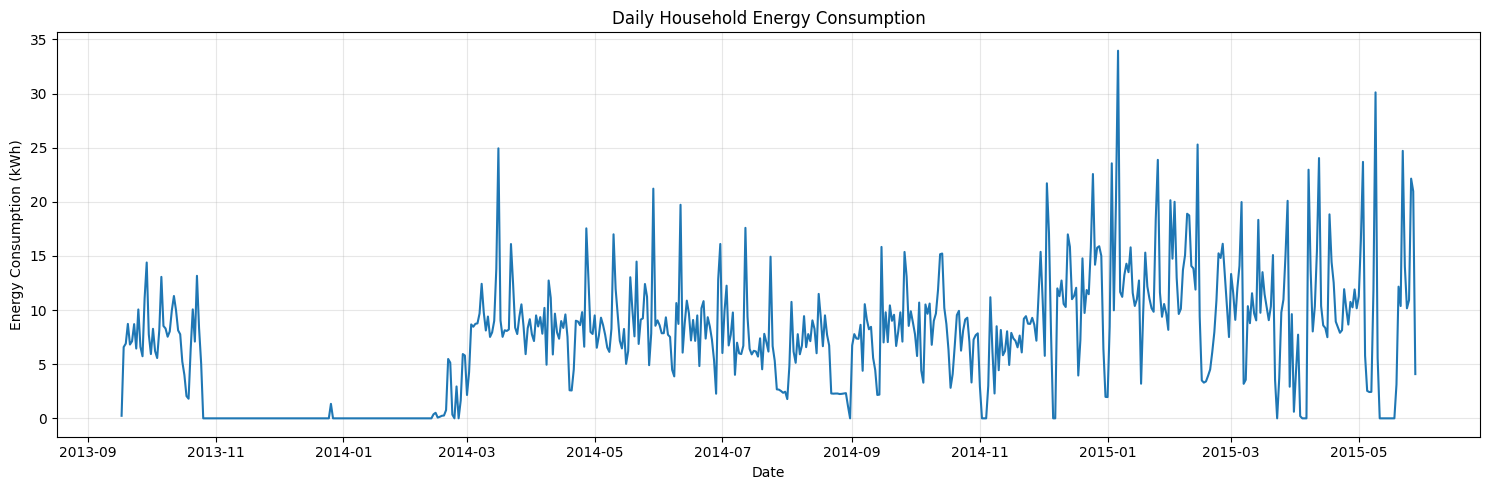

In [42]:
daily_energy = (
    combined_clean
    .set_index("Time")["Energy_kWh"]
    .resample("D")
    .sum()
)

plt.figure(figsize=(15, 5))

plt.plot(daily_energy.index, daily_energy.values)

plt.xlabel("Date")
plt.ylabel("Energy Consumption (kWh)")
plt.title("Daily Household Energy Consumption")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

There is very little energy consumption in Nov 2013 to March 2014

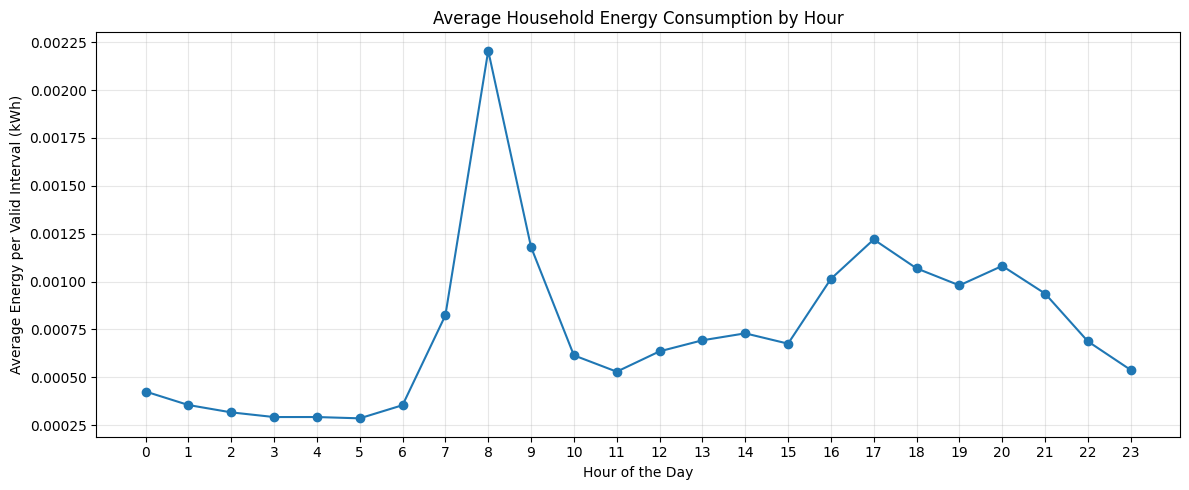

In [43]:
hourly_energy = (
    combined_clean
    .groupby(combined_clean["Time"].dt.hour)["Energy_kWh"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_energy.index,
    hourly_energy.values,
    marker="o"
)

plt.xlabel("Hour of the Day")
plt.ylabel("Average Energy per Valid Interval (kWh)")
plt.title("Average Household Energy Consumption by Hour")

plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The energy consumption peaks in the morning and a little peak is observed in the evening for the monitored appliances.

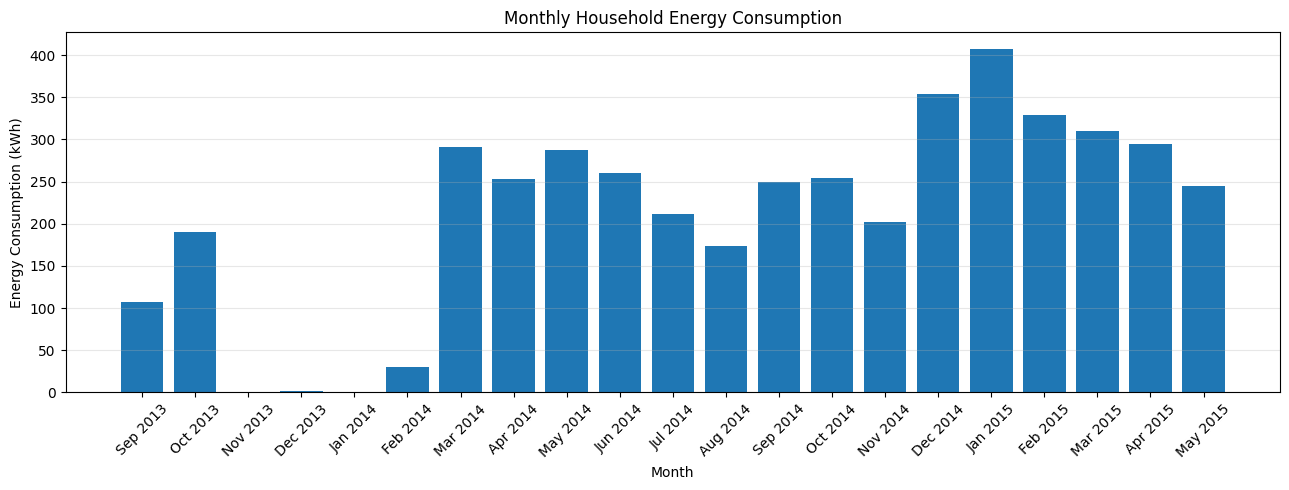

In [44]:
monthly_energy = (
    combined_clean
    .set_index("Time")["Energy_kWh"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(13, 5))

plt.bar(
    monthly_energy.index.strftime("%b %Y"),
    monthly_energy.values
)

plt.xlabel("Month")
plt.ylabel("Energy Consumption (kWh)")
plt.title("Monthly Household Energy Consumption")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The above graphs show us the monthly variation of the energy consumption, it is almost negligible for Nov 2013 to Jan 2014.

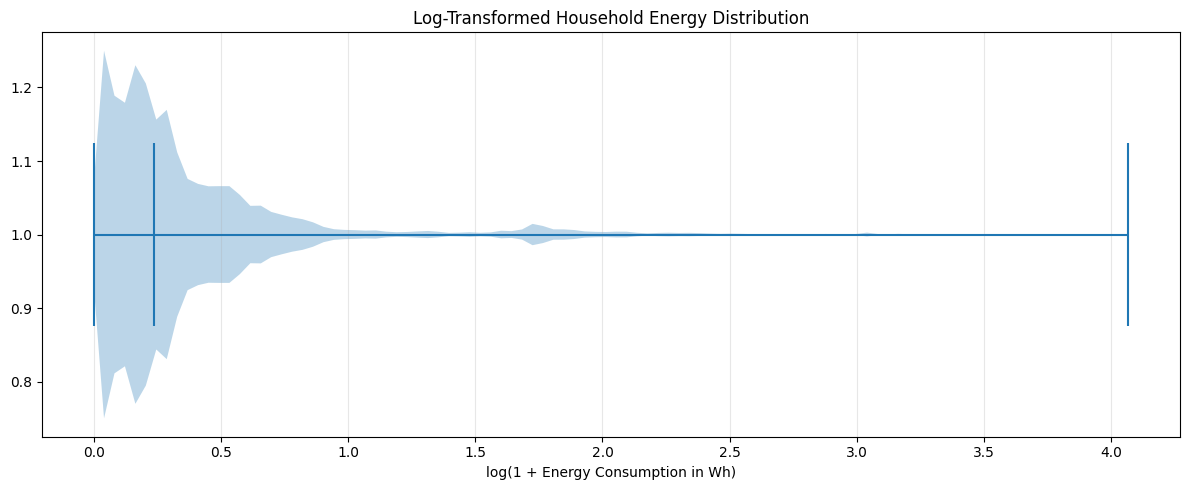

In [45]:
energy_values = combined_clean["Energy_Wh"].dropna()

log_energy = np.log1p(energy_values)

plt.figure(figsize=(12, 5))

plt.violinplot(
    log_energy,
    vert=False,
    showmedians=True,
    showextrema=True
)

plt.xlabel("log(1 + Energy Consumption in Wh)")
plt.title("Log-Transformed Household Energy Distribution")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

This log-transformed violin plot shows us the distribution of the energy consumption of the household.

### 5.2 Comparing energy consumption of appliances

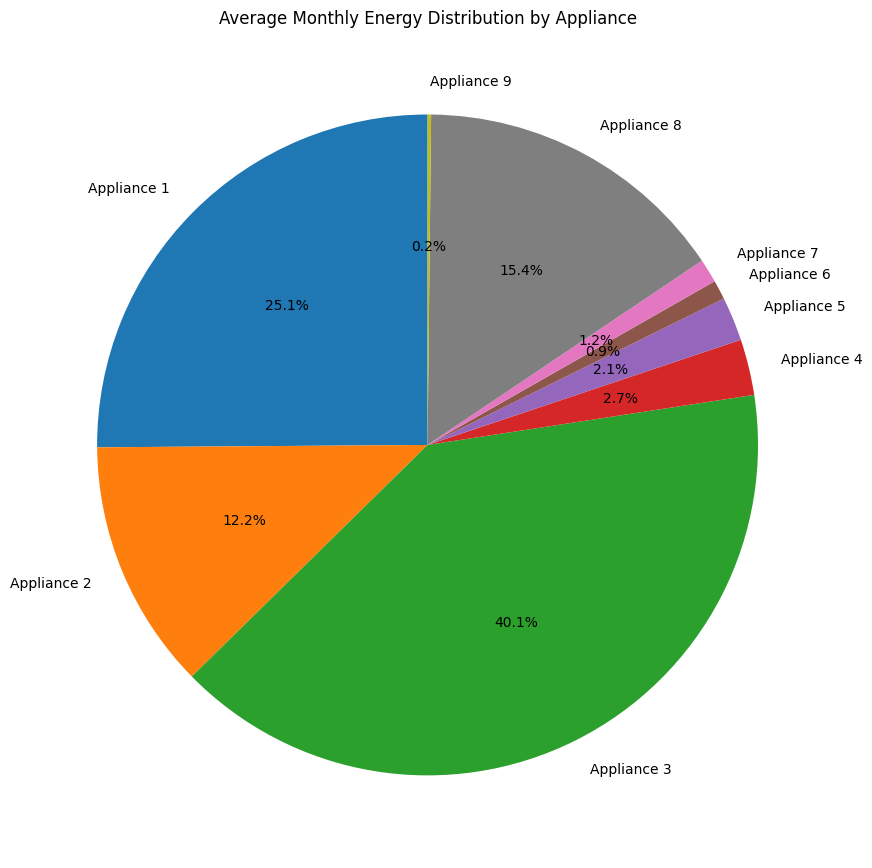

In [46]:

import matplotlib.pyplot as plt

# Select the monthly energy columns of all 9 appliances
appliance_energy_columns = [
    f"Appliance{i}_Energy_kWh"
    for i in range(1, 10)
]

# Calculate average monthly energy for each appliance
average_appliance_energy = (
    final_feature_dataset[appliance_energy_columns].mean()
)

# Create readable labels
appliance_labels = [
    f"Appliance {i}" for i in range(1, 10)
]

# Plot pie chart
plt.figure(figsize=(9, 9))

plt.pie(
    average_appliance_energy,
    labels=appliance_labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Average Monthly Energy Distribution by Appliance")
plt.tight_layout()
plt.show()

We can observe that appliance 3 (Dishwasher) contributes the most to the average monthly consumption.

### 5.3 Correlation Analysis

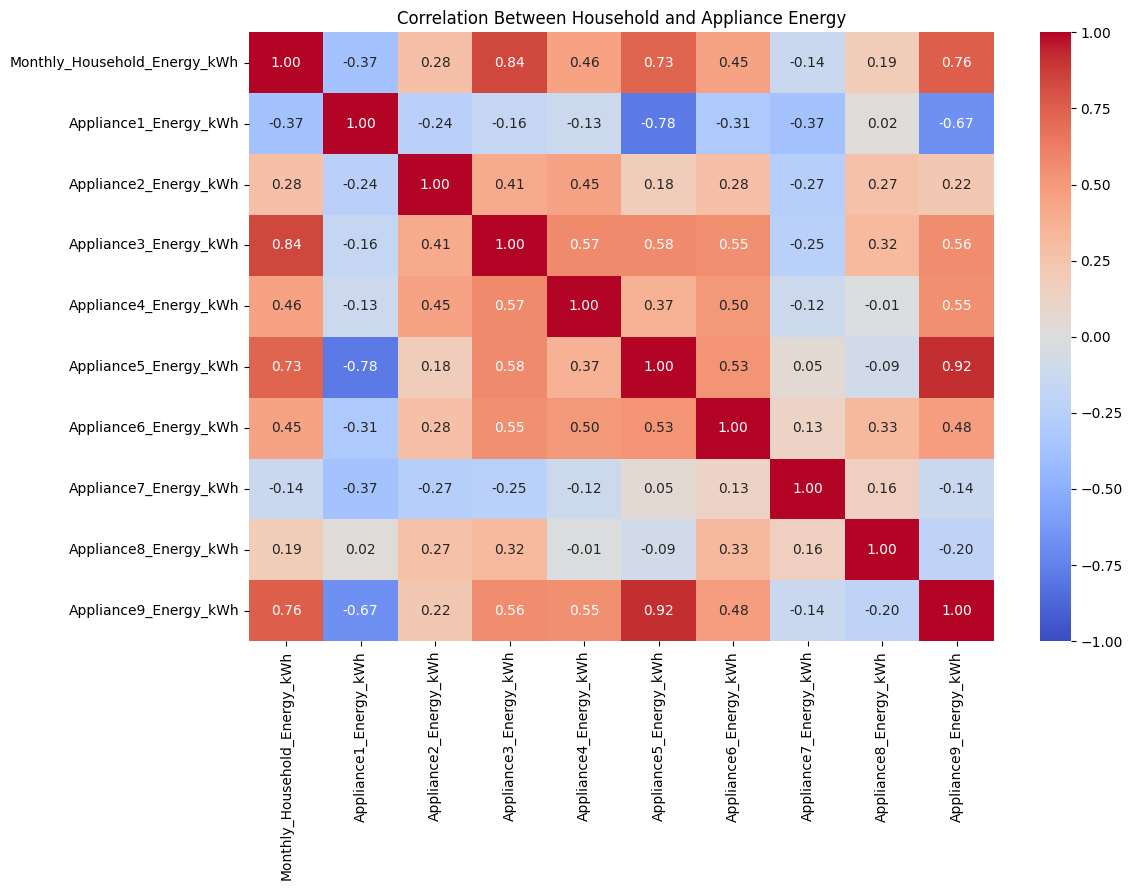

In [47]:
correlation_columns = [
    "Monthly_Household_Energy_kWh"
] + [
    f"Appliance{i}_Energy_kWh"
    for i in range(1, 10)
]

correlation_matrix = (
    final_feature_dataset[correlation_columns].corr()
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Household and Appliance Energy")
plt.tight_layout()
plt.show()

We can see that increase in use of appliance 5 (Microwave) is also seen with increase in use of appliance 9(Oven extractor fan), which makes sense because when the microwave is turned on, the fan i always turned on.

Increase in use of appliance 5 (Microwave) is seen with decrease in use of appliance 1 (Fridge-Freezer), it may be because when the weather is hot cool things are prefereed and when the weather is cold, warm things are preferred.

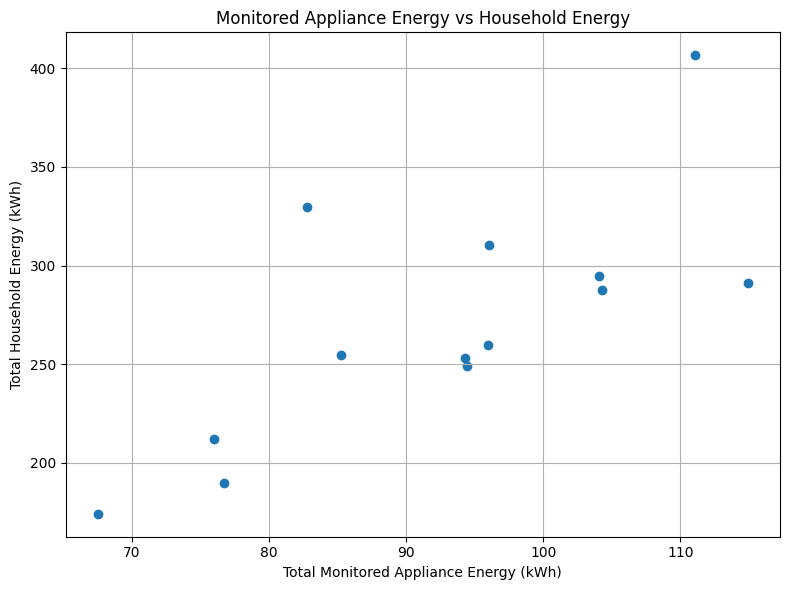

In [48]:
plt.figure(figsize=(8, 6))

plt.scatter(
    energy_validation["Total_Monitored_Energy_kWh"],
    energy_validation["Monthly_Household_Energy_kWh"]
)

plt.xlabel("Total Monitored Appliance Energy (kWh)")
plt.ylabel("Total Household Energy (kWh)")
plt.title("Monitored Appliance Energy vs Household Energy")
plt.grid(True)
plt.tight_layout()
plt.show()

This scatter plot shows the relation between the total household energy calculated by aggregate and the total energy that was consumed by the 9 monitored appliances.